# Change in fastball velocity after return and subsequent arm injury in MLB pitchers (v6)

**Research question.** Among MLB pitchers who experienced an initial arm injury, is a change in fastball
velocity in either direction (velocity lost or velocity gained), relative to their own pre-injury baseline,
upon returning to play associated with the risk of a subsequent arm injury during the same season,
controlling for age and role? Does the association differ between starters and relievers?

**Design** (following Brown & Do, 2022, *Research in Sports Medicine*: post- minus pre-injury differences,
logistic regression, group comparison of the differences), adapted for velocity:

* **Unit**: pitcher-season with an initial arm IL placement, first return by August 31, at least 5
  post-return appearances. Each season is its own unit (no carry-over).
* **Role (new in v6)**: starter = more than 3.0 innings per appearance in the pre-injury window; reliever =
  3.0 or fewer. No "mixed" group.
* **Landmark (new in v6)**: exposure = his **first 300 primary fastballs back**; outcome = a subsequent arm IL
  placement that season **after** the appearance with the 300th fastball. Counting fastballs instead of
  appearances gives starters and relievers equally precise exposures.
* **Exposures**: post-return minus pre-injury mean fastball velocity, split into **mph lost** and **mph
  gained**; and the difference in average within-game CV.
* **Analysis**: Table 1, Table 2 (by role), logistic regression (primary: adjusted for age, role and IL era;
  prespecified role interaction), pitcher-clustered 95% CIs, predicted risk by role, sensitivity analyses.
* **Seasons**: 2016–2019 and 2021–2026 pooled. 2015 left out (baselines reach into 2014 PITCHf/x data); 2020
  left out (60-game season). Injury rows: rebuilt from MLB transactions for 2016–2019 and FanGraphs for
  2021–2026, row-bound (see the notes in Section 13).
* **Eras**: the IL minimum changed (15 days → 10 in 2017 → 15 for pitchers in 2022), so the model adjusts for
  IL era; the pitch-tracking system changed (PITCHf/x → TrackMan 2017 → Hawk-Eye 2020), checked in Section 12.

Outputs go to `data/arm_velocity_logistic_v6/`. Run top to bottom; all rules are in the Settings cell.

## 1. Settings

In [1]:
from pathlib import Path
import io
import re
import time
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

WORKSPACE = Path.cwd()
DATA_DIR = WORKSPACE / "data"
DATA_DIR.mkdir(exist_ok=True)
STATCAST_CACHE = DATA_DIR / "statcast"              # shared with the replication notebook
STATCAST_CACHE.mkdir(exist_ok=True)
CHADWICK_CACHE = DATA_DIR / "chadwick_register_ids.csv"
OUT_DIR = DATA_DIR / "arm_velocity_logistic_v6"
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
INJURY_WORKBOOK = Path('/workspaces/Sports-Analytics-and-Intelligence-Lab/MLB Injuries/MLB Injuries Raw Data 2015-2026.xlsx')
if not INJURY_WORKBOOK.exists():
    raise FileNotFoundError(f"Expected workbook was not found: {INJURY_WORKBOOK}")

# ---- Seasons ----
SEASONS = [2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025, 2026]   # all pooled; no 2015, no 2020
TRAIN_SEASONS = SEASONS             # every season is analysed (name kept for the shared cohort code)

# ---- Cohort rules ----
PITCHER_POSITIONS = {"RP", "SP", "SP/RP", "RP/SP", "P"}
FIRST_RETURN_CUTOFF = "08-31"       # first return by August 31 (as in the WHIP paper)
MIN_POST_RETURN_APPS = 5            # at least 5 post-return appearances (as in the WHIP paper)
PATTERNS = {
    "elbow": re.compile(r"elbow|\bucl\b|ulnar|tommy john|flexor|pronator|forearm|epicondyl|olecranon|"
                        r"valgus|internal brace", flags=re.IGNORECASE),
    "arm":   re.compile(r"elbow|\bucl\b|ulnar|tommy john|flexor|pronator|forearm|epicondyl|olecranon|"
                        r"valgus|internal brace|shoulder|rotator|labrum|\bbicep|\btricep|\barm\b|\blat\b|"
                        r"latissimus|teres|thoracic outlet|capsul", flags=re.IGNORECASE),
}
INITIAL_GROUP = "arm"               # "arm" or "elbow": which initial IL placements define the cohort
SUBSEQUENT_GROUP = "arm"            # "arm" or "elbow": which later placement counts as a case
OUTCOME_LABEL = SUBSEQUENT_GROUP    # used in figure titles
COVID_PATTERN = re.compile(r"covid", flags=re.IGNORECASE)

# ---- Game-level statistics ----
FASTBALLS = ["FF", "SI"]            # primary fastball = whichever he threw more before the injury
LOOKBACK_DAYS = 365                 # baseline window before the initial arm injury
MIN_FB_GAME = 8                     # a game needs >= 8 primary fastballs to give a mean / SD / CV
FIRST_N_FB = 20                     # sensitivity analysis: CV from the first 20 primary fastballs
REST_CAP = 10                       # (kept from v3; not used by the charts)
SHRINK_BY_ROLE = True               # shrink each pitcher toward his role's mean (starter / reliever / mixed)
MIN_UNITS_ROLE_FIT = 10             # a role needs >= 10 training units for its own fit (else league-wide)

# ---- Pitch-tracking systems and IL-rule eras ----
TRACKING_SYSTEMS = [("PITCHf/x", "2008-01-01"), ("TrackMan", "2017-01-01"), ("Hawk-Eye", "2020-01-01")]
BASELINE_SAME_SYSTEM = False        # True: baselines use only games tracked by the monitored season's system
IL_ERAS = [("15-day DL (2015-16)", 2015), ("10-day DL/IL (2017-21)", 2017), ("15-day IL, pitchers (2022-)", 2022)]
STRATIFY_BY_ERA = True              # Mantel-Haenszel risk ratios stratified by role x IL era (else role only)


def tracking_system(dates):
    """System that tracked pitches on these dates (array-like of timestamps)."""
    d = pd.to_datetime(pd.Series(dates)).to_numpy()
    out = np.full(len(d), TRACKING_SYSTEMS[0][0], dtype=object)
    for name, start in TRACKING_SYSTEMS[1:]:
        out[d >= np.datetime64(start)] = name
    return out


def il_era(season):
    return [name for name, start in IL_ERAS if season >= start][-1]


# ---- Landmark logistic regression ----
LANDMARK_FB = 100                   # exposure = first 100 primary fastballs back; outcome = arm IL after that appearance
LANDMARK_FB_SENS = (100, 150)       # sensitivity analyses
LANDMARK = LANDMARK_FB              # (name kept for shared code)
ROLE_IP_CUTOFF = 3.0                # starter = more than 3.0 innings per appearance (pre-injury window)
ROLE_CUTOFF_SENS = (2.5, 4.0)       # sensitivity analyses
BF_PER_INNING = 4.25                # fallback when no MLB game log: innings ~ batters faced / 4.25
MIN_BASE_GAMES = 3                  # pre-injury games with >= MIN_FB_GAME primary fastballs (for CV)
MIN_LANDMARK_GAMES = 2              # qualifying games among the landmark appearances (for CV)
CV_SCALE = 0.1                      # CV odds ratios are per 0.1 percentage points
SEED = 2026

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()


print("Seasons analysed:", SEASONS, "| landmark:", LANDMARK_FB, "primary fastballs back | starter: >", ROLE_IP_CUTOFF, "IP per appearance")
print("Outputs:", OUT_DIR)

Seasons analysed: [2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025, 2026] | landmark: 100 primary fastballs back | starter: > 3.0 IP per appearance
Outputs: /workspaces/Sports-Analytics-and-Intelligence-Lab/MLB Pitcher Injuries/data/arm_velocity_logistic_v6


## 2. Injury records

Loads every season sheet, keeps pitcher rows with an IL date, and classifies each description as arm /
not arm and COVID / not COVID. Pitchers are keyed by **FanGraphs ID** rather than name, so accented
names cannot break the join (the issue behind the Table 2 baseline row). If a sheet has no
`key_fangraphs` column, the ID is read from the FanGraphs URL. Rows rebuilt from MLB transactions
(2015–2019) also carry `key_mlbam`, which is used directly for Statcast.

Rebuilt rows whose transaction gave **no injury text** cannot be classified; they count as non-arm (an
initial placement is missed; a later one stops a control). The table shows how many there are per season.

For the baseline window, the injury date is the **earlier** of the injury/surgery date and the IL date.
This matters for stints carried over from a previous season (e.g. Tommy John surgery the year before):
their IL date is opening day, but the pre-injury games are the ones before the surgery.

In [2]:
def clean_id(value):
    """IDs as plain strings: 12447.0 -> '12447', ' sa3012 ' -> 'sa3012'."""
    if pd.isna(value):
        return None
    text = str(value).strip()
    if not text:
        return None
    return text[:-2] if text.endswith(".0") else text


def fangraphs_id(row):
    value = clean_id(row.get("key_fangraphs"))
    if value:
        return value
    for column in ["URL", "sub_url"]:
        text = row.get(column)
        if isinstance(text, str):
            match = (re.search(r"/players/[^/]+/([^/?#]+)", text)
                     or re.match(r"[^/]+/([^/?#]+)/", text))
            if match:
                return match.group(1)
    return None


excel_file = pd.ExcelFile(INJURY_WORKBOOK)
tables = []
for sheet in excel_file.sheet_names:
    try:
        season = int(str(sheet).strip())
    except ValueError:
        continue
    if season in SEASONS:
        table = pd.read_excel(excel_file, sheet_name=sheet)
        table["Season"] = season
        tables.append(table)
missing_sheets = sorted(set(SEASONS) - {int(t["Season"].iloc[0]) for t in tables if len(t)})
if missing_sheets:
    raise ValueError(f"Workbook has no sheet for seasons {missing_sheets}")

injuries = pd.concat(tables, ignore_index=True).rename(columns={
    "IL Retro Date": "IL_Date", "Return Date": "Return_Date",
    "Injury / Surgery": "Injury", "Injury / Surgery Date": "Injury_Date"})
for column in ["IL_Date", "Return_Date", "Injury_Date"]:
    if column not in injuries.columns:
        injuries[column] = pd.NaT
    injuries[column] = pd.to_datetime(injuries[column], errors="coerce")

injuries["Pos"] = injuries["Pos"].astype(str).str.strip().str.upper()
injuries["Injury"] = injuries["Injury"].fillna("").astype(str).str.strip()
injuries["FanGraphs_ID"] = injuries.apply(fangraphs_id, axis=1)
injuries["MLBAM_ID"] = injuries["key_mlbam"].map(clean_id) if "key_mlbam" in injuries else None
injuries["pkey"] = injuries["FanGraphs_ID"].where(
    injuries["FanGraphs_ID"].notna(),
    ("mlbam:" + injuries["MLBAM_ID"].astype(str)).where(injuries["MLBAM_ID"].notna(), "name:" + injuries["Name"].astype(str)))
injuries = injuries.loc[injuries["Pos"].isin(PITCHER_POSITIONS) & injuries["IL_Date"].notna()].copy()
injuries = injuries.drop_duplicates(["pkey", "Season", "IL_Date", "Injury"])
injuries["is_covid"] = injuries["Injury"].str.contains(COVID_PATTERN)
non_throwing = injuries["Injury"].str.contains("non-throwing", case=False)
for group, pattern in PATTERNS.items():
    injuries[f"is_{group}"] = injuries["Injury"].str.contains(pattern) & ~non_throwing
injuries["is_initial"] = injuries[f"is_{INITIAL_GROUP}"]
injuries["is_subseq"] = injuries[f"is_{SUBSEQUENT_GROUP}"]
injuries["onset"] = injuries[["Injury_Date", "IL_Date"]].min(axis=1)
injuries = injuries.sort_values(["pkey", "Season", "IL_Date"], kind="stable").reset_index(drop=True)

display(injuries.groupby("Season").agg(pitcher_IL_rows=("pkey", "size"),
                                      initial_type_rows=("is_initial", "sum"),
                                      subsequent_type_rows=("is_subseq", "sum"),
                                      covid_rows=("is_covid", "sum"),
                                      blank_injury_text=("Injury", lambda s: int((s == "").sum())),
                                      missing_fangraphs_id=("FanGraphs_ID", lambda s: int(s.isna().sum()))))

# Every description and how it was classified, for a line-by-line check of the rule.
classification_review = (injuries.loc[~injuries["is_covid"]]
                         .groupby(["is_arm", "is_elbow", "Injury"]).size().rename("IL rows").reset_index()
                         .sort_values(["is_arm", "is_elbow", "IL rows"], ascending=[False, False, False]))
classification_review.to_csv(OUT_DIR / "injury_classification_review.csv", index=False)
print(f"Initial injury group: {INITIAL_GROUP} | subsequent injury group: {SUBSEQUENT_GROUP}")
print("Arm descriptions (is_elbow marks the elbow subset):")
with pd.option_context("display.max_rows", 300):
    display(classification_review.loc[classification_review["is_arm"]])
print("Most common non-arm descriptions (full list in injury_classification_review.csv):")
display(classification_review.loc[~classification_review["is_arm"]].head(30))

,pitcher_IL_rows,initial_type_rows,subsequent_type_rows,covid_rows,blank_injury_text,missing_fangraphs_id
Season,,,,,,
2016,302,174,174,0,3,2
2017,383,184,184,0,22,4
2018,432,219,219,0,9,2
2019,400,225,225,0,11,1
2021,687,303,303,130,0,0
2022,559,285,285,10,0,0
2023,502,293,293,2,0,0
2024,483,320,320,2,0,0
2025,458,292,292,0,0,0


Initial injury group: arm | subsequent injury group: arm
Arm descriptions (is_elbow marks the elbow subset):


,is_arm,is_elbow,Injury,IL rows
1127,True,True,Tommy John surgery,309
914,True,True,Elbow inflammation,158
1118,True,True,Strained forearm,76
1072,True,True,Right elbow inflammation,35
905,True,True,Elbow discomfort,34
...,...,...,...,...
880,True,False,Triceps discomfort,1
882,True,False,Triceps soreness,1
885,True,False,Vascular surgery (upper arm aneurysm),1
886,True,False,inflammation in left shoulder,1


Most common non-arm descriptions (full list in injury_classification_review.csv):


,is_arm,is_elbow,Injury,IL rows
562,False,False,Strained oblique,123
544,False,False,Strained hamstring,104
543,False,False,Strained groin,82
628,False,False,Undisclosed,63
557,False,False,Strained lower back,52
0,False,False,,45
535,False,False,Strained calf,38
191,False,False,Knee inflammation,33
267,False,False,Left oblique strain,31
508,False,False,Sprained ankle,24


## 3. Cohort: initial arm IL placement → subsequent arm IL placement

For each pitcher-season, the **initial** placement is his first arm placement of that season. The
**next** non-COVID placement after his return decides the outcome: arm → case (chart runs up to that IL
date); anything else → control, chart stops at that IL date; none → control, chart runs to the end of the
season.

In [3]:
initial_rows = injuries.loc[injuries["is_initial"] & ~injuries["is_covid"]]
units = (initial_rows.groupby(["pkey", "Season"], as_index=False, sort=False).head(1)
              [["pkey", "Name", "Season", "FanGraphs_ID", "MLBAM_ID", "Team", "Pos", "Injury", "Injury_Date",
                "IL_Date", "onset", "Return_Date"]]
              .rename(columns={"Injury": "initial_injury"})
              .reset_index(drop=True))
funnel = [("Pitcher-seasons with an arm IL placement", len(units))]

cutoff = pd.to_datetime(units["Season"].astype(str) + "-" + FIRST_RETURN_CUTOFF)
units = units.loc[units["Return_Date"].notna()]
funnel.append(("... with a return date", len(units)))
units = units.loc[units["Return_Date"] >= units["IL_Date"]]
funnel.append(("... return on or after the IL date", len(units)))
units = units.loc[units["Return_Date"] <= cutoff.loc[units.index]].copy()
funnel.append((f"... first return by {FIRST_RETURN_CUTOFF}", len(units)))

# Next non-COVID IL placement after the return, same season.
later = injuries.loc[~injuries["is_covid"], ["pkey", "Season", "IL_Date", "Injury", "is_subseq"]].merge(
    units[["pkey", "Season", "Return_Date"]], on=["pkey", "Season"])
later = later.loc[later["IL_Date"] > later["Return_Date"]].sort_values(["pkey", "Season", "IL_Date"])
next_il = later.groupby(["pkey", "Season"], as_index=False).head(1)
any_later_subseq = later.loc[later["is_subseq"]].groupby(["pkey", "Season"]).size().rename("n_later_subseq")

units = units.merge(next_il[["pkey", "Season", "IL_Date", "Injury", "is_subseq"]]
                    .rename(columns={"IL_Date": "next_il_date", "Injury": "next_injury",
                                     "is_subseq": "next_is_subseq"}),
                    on=["pkey", "Season"], how="left")
units = units.merge(any_later_subseq, left_on=["pkey", "Season"], right_index=True, how="left")
units["next_is_subseq"] = units["next_is_subseq"].astype("boolean").fillna(False).astype(bool)
units["case"] = units["next_is_subseq"].astype(int)
units["event_date"] = units["next_il_date"].where(units["case"] == 1)
units["censor_date"] = units["next_il_date"].where(units["case"] == 0)
units["stop_date"] = units["next_il_date"].fillna(pd.to_datetime(units["Season"].astype(str) + "-12-31")
                                                  + pd.Timedelta(days=1))
units["outcome"] = np.select(
    [units["case"] == 1, units["censor_date"].notna()],
    ["case: subsequent arm IL", "control: stopped at non-arm IL"],
    default="control: no later IL")

n_subseq_after_other = int(((units["case"] == 0) & units["n_later_subseq"].notna()).sum())
print("Controls whose next placement was non-arm but who had an arm placement later that season:",
      n_subseq_after_other, "(kept as controls, as specified)")
display(pd.crosstab(units["Season"], units["outcome"], margins=True))

Controls whose next placement was non-arm but who had an arm placement later that season: 9 (kept as controls, as specified)


outcome,case: subsequent arm IL,control: no later IL,control: stopped at non-arm IL,All
Season,,,,
2016,10,52,1,63
2017,21,56,12,89
2018,25,73,13,111
2019,24,70,17,111
2021,32,75,22,129
2022,28,64,19,111
2023,23,74,19,116
2024,33,78,15,126
2025,27,63,17,107


## 4. MLBAM IDs and Baseball Savant pitch data

Statcast uses MLBAM IDs, linked to FanGraphs IDs by the Chadwick register (cached by the replication
notebook; downloaded here if missing). Each pitcher's window runs from 365 days before the initial arm
injury to November 30 of the monitored season. Cached files from the replication notebook are used when
they cover the window; otherwise only the missing earlier dates are downloaded and cached as a separate
file.

In [4]:
CHADWICK_URL = "https://raw.githubusercontent.com/chadwickbureau/register/master/data/people-{}.csv"
if CHADWICK_CACHE.exists():
    id_map = pd.read_csv(CHADWICK_CACHE, dtype=str)
else:
    parts = []
    for suffix in "0123456789abcdef":
        part = pd.read_csv(CHADWICK_URL.format(suffix), usecols=["key_mlbam", "key_fangraphs"],
                           dtype=str, low_memory=False)
        parts.append(part.dropna())
        time.sleep(0.5)
    id_map = pd.concat(parts, ignore_index=True)
    id_map.to_csv(CHADWICK_CACHE, index=False)
fg_to_mlbam = dict(zip(id_map["key_fangraphs"].map(clean_id), id_map["key_mlbam"].map(clean_id)))

units["mlbam"] = units["MLBAM_ID"].where(units["MLBAM_ID"].notna(),
                                         units["FanGraphs_ID"].map(lambda v: fg_to_mlbam.get(v) if v else None))
no_id = units.loc[units["mlbam"].isna(), ["Name", "Season", "FanGraphs_ID"]]
if len(no_id):
    print("No MLBAM ID (dropped):")
    display(no_id)
units = units.loc[units["mlbam"].notna()].copy()
units["mlbam"] = units["mlbam"].astype(int)
funnel.append(("... with an MLBAM ID", len(units)))
units["window_start"] = (units["onset"] - pd.Timedelta(days=LOOKBACK_DAYS)).dt.normalize()
units["window_end"] = pd.to_datetime(units["Season"].astype(str) + "-11-30")
print("Pitcher-seasons to download:", len(units))

No MLBAM ID (dropped):


,Name,Season,FanGraphs_ID
832,Coleman Crow,2026,27926
836,Wilber Dotel,2026,28901
838,Kendry Rojas,2026,29423
861,Marco Raya,2026,30166
915,Tatsuya Imai,2026,37124
1082,Dylan File,2021,sa3004197
1083,Shane Drohan,2024,sa3014447
1084,Daniel Tillo,2021,sa876284


Pitcher-seasons to download: 1077


In [5]:
SAVANT_URL = (
    "https://baseballsavant.mlb.com/statcast_search/csv?all=true&type=details&player_type=pitcher"
    "&hfGT=R%7C&hfSea=&game_date_gt={start}&game_date_lt={end}&pitchers_lookup%5B%5D={mlbam}"
    "&min_pitches=0&min_results=0&min_abs=0&group_by=name&sort_col=pitches&sort_order=desc"
)
SAVANT_KEEP = ["pitcher", "game_pk", "game_date", "game_type", "inning", "at_bat_number",
               "pitch_number", "pitch_type", "release_speed", "p_throws"]
CACHE_NAME = re.compile(r"(\d+)_(\d{8})_(\d{8})\.csv")


def download_statcast(mlbam, start, end, sleep_seconds=2.0, retries=3):
    """One Savant request (regular season), saved in the shared cache with the same file naming."""
    path = STATCAST_CACHE / f"{mlbam}_{start:%Y%m%d}_{end:%Y%m%d}.csv"
    if path.exists():
        return pd.read_csv(path)
    url = SAVANT_URL.format(mlbam=mlbam, start=f"{start:%Y-%m-%d}", end=f"{end:%Y-%m-%d}")
    for attempt in range(1, retries + 1):
        try:
            time.sleep(sleep_seconds)
            request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urlopen(request, timeout=120) as response:
                text = response.read().decode("utf-8-sig")
            break
        except Exception as error:
            print(f"  attempt {attempt} failed for {mlbam}: {error!r}")
            time.sleep(10 * attempt)
    else:
        raise RuntimeError(f"Could not download Statcast data for pitcher {mlbam}")
    data = pd.read_csv(io.StringIO(text)) if text.strip() else pd.DataFrame(columns=SAVANT_KEEP)
    required = set(SAVANT_KEEP) - {"p_throws"}
    if len(data) and required - set(data.columns):
        raise ValueError(f"Unexpected Savant response for {mlbam}: {text[:300]!r}")
    if "game_type" in data.columns:
        data = data.loc[data["game_type"] == "R"]
    data = data[[c for c in SAVANT_KEEP if c in data.columns]]
    data.to_csv(path, index=False)
    return data


def cached_files(mlbam):
    out = []
    for path in STATCAST_CACHE.glob(f"{mlbam}_*.csv"):
        match = CACHE_NAME.fullmatch(path.name)
        if match and int(match.group(1)) == mlbam:
            out.append((pd.Timestamp(match.group(2)), pd.Timestamp(match.group(3)), path))
    return out


def statcast_window(mlbam, start, end):
    """Pitches for [start, end], from the cache where possible; downloads only the uncovered part."""
    files = cached_files(mlbam)
    pieces = [pd.read_csv(p) for s, e, p in files if s <= end and e >= start]   # overlapping files
    covered_from = min([s for s, e, p in files if s <= end and e >= end], default=None)
    if covered_from is None:                       # nothing reaches the end date: one full request
        pieces.append(download_statcast(mlbam, start, end))
    elif covered_from > start:                     # fetch only the earlier, uncovered dates
        pieces.append(download_statcast(mlbam, start, covered_from - pd.Timedelta(days=1)))
    pieces = [p for p in pieces if len(p)]
    if not pieces:
        return pd.DataFrame(columns=SAVANT_KEEP)
    data = pd.concat(pieces, ignore_index=True)
    data["game_date"] = pd.to_datetime(data["game_date"])
    return data.loc[data["game_date"].between(start, end)]


pieces, statcast_failures = [], []
for number, (_, row) in enumerate(units.drop_duplicates(["mlbam", "window_start", "window_end"]).iterrows(), 1):
    try:
        pieces.append(statcast_window(row["mlbam"], row["window_start"], row["window_end"]))
    except Exception as error:
        statcast_failures.append({"Name": row["Name"], "Season": row["Season"], "mlbam": row["mlbam"],
                                  "error": repr(error)})
    if number % 50 == 0:
        print(f"{number} windows ({len(statcast_failures)} failures)")
statcast_failures = pd.DataFrame(statcast_failures)
statcast_failures.to_csv(OUT_DIR / "statcast_fetch_failures.csv", index=False)
if len(statcast_failures):
    display(statcast_failures)

pitches = pd.concat(pieces, ignore_index=True)
if "p_throws" not in pitches.columns:
    pitches["p_throws"] = np.nan
pitches = pitches.dropna(subset=["game_pk", "at_bat_number", "pitch_number"]).copy()
pitches["pitcher"] = pitches["pitcher"].astype(int)
pitches["game_pk"] = pitches["game_pk"].astype(int)
pitches["game_date"] = pd.to_datetime(pitches["game_date"])
pitches = (pitches.drop_duplicates(["pitcher", "game_pk", "at_bat_number", "pitch_number"])
                  .sort_values(["pitcher", "game_date", "game_pk", "at_bat_number", "pitch_number"])
                  .reset_index(drop=True))
pitches["pitch_count"] = pitches.groupby(["pitcher", "game_pk"]).cumcount() + 1
pitches_by_pitcher = {p: g for p, g in pitches.groupby("pitcher")}
print(f"Pitches: {len(pitches):,} | pitchers: {pitches['pitcher'].nunique()}")

50 windows (1 failures)
100 windows (2 failures)
150 windows (2 failures)
200 windows (3 failures)
250 windows (5 failures)
300 windows (6 failures)
350 windows (9 failures)
400 windows (11 failures)
450 windows (17 failures)
500 windows (20 failures)
550 windows (23 failures)
600 windows (29 failures)
650 windows (34 failures)
700 windows (41 failures)
750 windows (53 failures)
800 windows (61 failures)
850 windows (66 failures)
900 windows (69 failures)
950 windows (70 failures)
1000 windows (70 failures)
1050 windows (74 failures)


,Name,Season,mlbam,error
0,Mike Minor,2022,501985,"NotImplementedError(""strftime not yet supporte..."
1,Tommy Kahnle,2023,592454,"NotImplementedError(""strftime not yet supporte..."
2,Dylan Floro,2022,571670,"NotImplementedError(""strftime not yet supporte..."
3,Lucas Sims,2022,608371,"NotImplementedError(""strftime not yet supporte..."
4,Josh Hader,2026,623352,"NotImplementedError(""strftime not yet supporte..."
...,...,...,...,...
70,Jay Jackson,2022,543351,"NotImplementedError(""strftime not yet supporte..."
71,Justin Verlander,2024,434378,"NotImplementedError(""strftime not yet supporte..."
72,Wade Miley,2022,489119,"NotImplementedError(""strftime not yet supporte..."
73,Wade Miley,2024,489119,"NotImplementedError(""strftime not yet supporte..."


Pitches: 1,653,886 | pitchers: 697


In [6]:
# Arm descriptions that name a side: flag any that do not match the throwing arm, for manual review.
throws = pitches.dropna(subset=["p_throws"]).groupby("pitcher")["p_throws"].agg(lambda s: s.mode().iat[0])
units["throws"] = units["mlbam"].map(throws)
side = units["initial_injury"].str.extract(r"\b(left|right)\b", flags=re.IGNORECASE, expand=False).str.upper().str[0]
side_check = units.assign(side=side).loc[lambda d: d["side"].notna()]
mismatch = side_check.loc[side_check["throws"].notna() & (side_check["side"] != side_check["throws"])]
print(f"Initial arm descriptions naming a side: {len(side_check)}; "
      f"side differs from the throwing arm: {len(mismatch)}")
if len(mismatch):
    display(mismatch[["Name", "Season", "initial_injury", "throws"]])

Initial arm descriptions naming a side: 348; side differs from the throwing arm: 13


,Name,Season,initial_injury,throws
227,Jon Moscot,2016,inflammation in left shoulder,R
250,Wandy Peralta,2019,Right hip flexor strain,L
257,Yohander Méndez,2019,Right UCL sprain,L
394,Harrison Musgrave,2018,Right hip flexor strain,L
422,Raisel Iglesias,2018,Left biceps strain,R
425,Domingo Germán,2019,Left hip flexor strain,R
839,Josh Ravin,2016,Left forearm fracture,R
881,Will Harris,2017,Left shoulder inflammation,R
941,Brandon McCarthy,2017,Left shoulder soreness,R
985,Steve Cishek,2016,Left hip labrum tear,R


## 5. Game-level fastball statistics

For each unit:

* **Primary fastball**: FF or SI, whichever he threw more in the 365 days before the injury (if he has no
  pre-injury fastballs, the post-return games decide).
* **Baseline games**: games in that pre-injury window with at least `MIN_FB_GAME` primary fastballs.
* **Monitored games**: games from the return date up to (not including) the stop date, with at least
  `MIN_FB_GAME` primary fastballs. Appearances with fewer fastballs leave the chart unchanged.
* **Post-return appearances** (for the 5-appearance rule) count every regular-season game after the return
  that season, as in the WHIP paper.
* **Tracking system**: each unit is flagged if any baseline game was tracked by a different system than his
  monitored games (PITCHf/x → TrackMan in 2017; TrackMan → Hawk-Eye in 2020). Section 13 reruns the
  comparison with baselines restricted to the same system.
* **Per-game statistics**: mean, SD and CV (= 100 × SD / mean) of primary-fastball velocity, and for the
  sensitivity analyses the CV of the first `FIRST_N_FB` fastballs and the CV of residuals around the game's
  own linear fade. Types are forced to numeric, which avoids the object-dtype `log` error.

In [7]:
def per_game(game_pitches, primary):
    """One row per game for the primary fastball: count, mean, SD, CV, plus two CV variants for the
    sensitivity analyses (first FIRST_N_FB fastballs; residuals around the game's own linear fade),
    and the logs of the three CVs. Games with fewer than MIN_FB_GAME primary fastballs are dropped."""
    cols = ["game_pk", "game_date", "n_fb", "velo", "sd", "cv", "cv_f20", "cv_resid", "n_pitches",
            "logcv", "logcv_f20", "logcv_resid"]
    fb = game_pitches.loc[game_pitches["pitch_type"] == primary,
                          ["game_pk", "game_date", "pitch_count", "release_speed"]].copy()
    fb["release_speed"] = pd.to_numeric(fb["release_speed"], errors="coerce").astype(float)
    fb["pitch_count"] = pd.to_numeric(fb["pitch_count"], errors="coerce").astype(float)
    fb = fb.dropna(subset=["release_speed", "pitch_count"])
    if fb.empty:
        return pd.DataFrame({c: pd.Series(dtype=float) for c in cols})
    grp = fb.groupby("game_pk")
    g = grp.agg(game_date=("game_date", "first"), n_fb=("release_speed", "size"),
                velo=("release_speed", "mean"), sd=("release_speed", "std")).reset_index()
    f20 = fb.groupby("game_pk", sort=False).head(FIRST_N_FB).groupby("game_pk")["release_speed"].agg(["mean", "std"])
    g["cv_f20"] = g["game_pk"].map(100 * f20["std"] / f20["mean"])
    xd = fb["pitch_count"] - grp["pitch_count"].transform("mean")
    yd = fb["release_speed"] - grp["release_speed"].transform("mean")
    slope = ((xd * yd).groupby(fb["game_pk"]).sum() / (xd ** 2).groupby(fb["game_pk"]).sum().replace(0, np.nan)).fillna(0)
    resid = yd - fb["game_pk"].map(slope) * xd
    sd_resid = np.sqrt((resid ** 2).groupby(fb["game_pk"]).sum() / (grp.size() - 2).clip(lower=1))
    g["cv"] = 100 * g["sd"] / g["velo"]
    g["cv_resid"] = 100 * g["game_pk"].map(sd_resid) / g["velo"]
    g["n_pitches"] = g["game_pk"].map(game_pitches.groupby("game_pk").size())
    g = g.loc[g["n_fb"] >= MIN_FB_GAME].sort_values(["game_date", "game_pk"]).reset_index(drop=True)
    for c in ["n_fb", "velo", "sd", "cv", "cv_f20", "cv_resid", "n_pitches"]:
        g[c] = pd.to_numeric(g[c], errors="coerce").astype(float)
    for c in ["cv", "cv_f20", "cv_resid"]:
        g["log" + c] = np.log(np.clip(g[c].to_numpy(float), 1e-6, None))
    return g[cols]


unit_data, drop_reason = {}, {}
units = units.reset_index(drop=True)
units["uid"] = units.index
for _, row in units.iterrows():
    g = pitches_by_pitcher.get(row["mlbam"])
    if g is None:
        drop_reason[row["uid"]] = "no Statcast pitches"
        continue
    season_end = pd.Timestamp(f"{int(row['Season'])}-12-31")
    pre = g.loc[(g["game_date"] >= row["window_start"]) & (g["game_date"] < row["onset"])]
    post = g.loc[(g["game_date"] >= row["Return_Date"]) & (g["game_date"] <= season_end)]
    monitored_raw = post.loc[post["game_date"] < row["stop_date"]]

    fb_counts = pre.loc[pre["pitch_type"].isin(FASTBALLS), "pitch_type"].value_counts()
    if fb_counts.empty:
        fb_counts = monitored_raw.loc[monitored_raw["pitch_type"].isin(FASTBALLS), "pitch_type"].value_counts()
    if fb_counts.empty:
        drop_reason[row["uid"]] = "no four-seam or sinker"
        continue
    primary = fb_counts.idxmax()

    apps = post.drop_duplicates("game_pk")[["game_pk", "game_date"]].sort_values(["game_date", "game_pk"])
    if len(apps) < MIN_POST_RETURN_APPS:
        drop_reason[row["uid"]] = f"fewer than {MIN_POST_RETURN_APPS} post-return appearances"
        continue
    apps_before_stop = apps.loc[apps["game_date"] < row["stop_date"]].reset_index(drop=True)
    monitored = per_game(monitored_raw, primary)
    if monitored.empty:
        drop_reason[row["uid"]] = "no monitored game with enough fastballs"
        continue
    pre_games = pre.groupby("game_pk")["inning"].min()
    ref_games = pre_games if len(pre_games) else monitored_raw.groupby("game_pk")["inning"].min()
    start_share = (ref_games == 1).mean() if len(ref_games) else np.nan
    role = ("unknown" if np.isnan(start_share) else "starter" if start_share >= 0.6
            else "reliever" if start_share <= 0.2 else "mixed")
    app_index = {pk: i for i, pk in enumerate(apps_before_stop["game_pk"])}
    monitored["app_index"] = monitored["game_pk"].map(app_index)      # 0 = first appearance back
    rest = apps_before_stop["game_date"].diff().dt.days.fillna(REST_CAP)   # first game back = long rest
    monitored["rest_days"] = monitored["game_pk"].map(dict(zip(apps_before_stop["game_pk"], rest)))
    base_games = per_game(pre, primary)
    season_system = tracking_system([row["Return_Date"]])[0]
    unit_data[row["uid"]] = {
        "season_system": season_system,
        "baseline_crosses_system": bool(len(base_games) and (tracking_system(base_games["game_date"]) != season_system).any()),
        "primary": primary,
        "role": role,
        "baseline": base_games,
        "monitored": monitored,
        "n_apps_before_stop": len(apps_before_stop),
        "n_post_return_apps": len(apps),
    }

units["dropped"] = units["uid"].map(drop_reason)
for reason, n in units["dropped"].value_counts().items():
    print(f"Dropped: {reason}: {n}")
units = units.loc[units["dropped"].isna()].drop(columns="dropped")   # index stays = uid
funnel.append((f"... with Statcast data, >= {MIN_POST_RETURN_APPS} post-return appearances, "
               "and >= 1 monitored game", len(units)))
units["split"] = "analysed"
units["primary"] = units["uid"].map(lambda u: unit_data[u]["primary"])
units["role"] = units["uid"].map(lambda u: unit_data[u]["role"])
units["baseline_games"] = units["uid"].map(lambda u: len(unit_data[u]["baseline"]))
units["monitored_games"] = units["uid"].map(lambda u: len(unit_data[u]["monitored"]))
units["era"] = units["Season"].map(il_era)
units["tracking_system"] = units["uid"].map(lambda u: unit_data[u]["season_system"])
units["baseline_crosses_system"] = units["uid"].map(lambda u: unit_data[u]["baseline_crosses_system"])

funnel = pd.DataFrame(funnel, columns=["step", "pitcher-seasons"])
funnel.to_csv(OUT_DIR / "cohort_funnel.csv", index=False)
display(funnel)
cohort_table = (units.groupby(["split", "Season"])
                     .agg(units=("uid", "size"), cases=("case", "sum"),
                          controls_stopped_at_other_IL=("censor_date", lambda s: int(s.notna().sum())),
                          median_baseline_games=("baseline_games", "median"),
                          no_baseline_games=("baseline_games", lambda s: int((s == 0).sum())),
                          median_monitored_games=("monitored_games", "median")))
display(cohort_table)
display(pd.crosstab([units["split"], units["role"]], units["case"].map({1: "case", 0: "control"})))
print("Reinjury rate by IL era (the IL minimum changes what reaches the IL):")
display(units.groupby(["split", "era"]).agg(units=("uid", "size"), cases=("case", "sum"),
                                           reinjury_rate=("case", "mean")).round(3))
print("Units whose baseline includes games from a different tracking system than their season:")
display(units.groupby(["split", "Season"])["baseline_crosses_system"].agg(["sum", "size"])
        .rename(columns={"sum": "baseline crosses system", "size": "units"}))
units.drop(columns=["window_start", "window_end"]).to_csv(OUT_DIR / "cohort_units.csv", index=False)

Dropped: fewer than 5 post-return appearances: 203
Dropped: no Statcast pitches: 49
Dropped: no monitored game with enough fastballs: 37
Dropped: no four-seam or sinker: 24


,step,pitcher-seasons
0,Pitcher-seasons with an arm IL placement,2307
1,... with a return date,1749
2,... return on or after the IL date,1748
3,... first return by 08-31,1085
4,... with an MLBAM ID,1077
5,"... with Statcast data, >= 5 post-return appea...",764


units  cases  controls_stopped_at_other_IL  \
split    Season                                               
analysed 2016       49      7                             1   
         2017       68     16                             8   
         2018       80     14                            11   
         2019       79     16                            13   
         2021       88     20                            16   
         2022       78     19                            15   
         2023       77     15                            14   
         2024       82     21                            10   
         2025       79     22                            11   
         2026       84     12                            13   

                 median_baseline_games  no_baseline_games  \
split    Season                                             
analysed 2016                     23.0                  1   
         2017                     26.0                  1   
         2018                     21.5                  5   
         2019                     24.0                  4   
         2021                     14.0                  3   
         2022                     19.0                  1   
         2023                     19.0                  5   
         2024                     20.5                  4   
         2025                     19.0                  5   
         2026                     19.0                  2   

                 median_monitored_games  
split    Season                          
analysed 2016                       9.0  
         2017                       9.0  
         2018                       7.0  
         2019                      10.0  
         2021                       7.5  
         2022                       8.0  
         2023                       8.0  
         2024                       8.0  
         2025                       8.0  
         2026                       9.0

case               case  control
split    role                   
analysed mixed       12       27
         reliever    83      321
         starter     67      254

Reinjury rate by IL era (the IL minimum changes what reaches the IL):


units  cases  reinjury_rate
split    era                                                     
analysed 10-day DL/IL (2017-21)         315     66          0.210
         15-day DL (2015-16)             49      7          0.143
         15-day IL, pitchers (2022-)    400     89          0.222

Units whose baseline includes games from a different tracking system than their season:


baseline crosses system  units
split    Season                                
analysed 2016                          0     49
         2017                         64     68
         2018                          2     80
         2019                          1     79
         2021                          4     88
         2022                          2     78
         2023                          0     77
         2024                          0     82
         2025                          0     79
         2026                          0     84

## 6. Age at return (Chadwick register birth dates)

Age is taken from the Chadwick register's birth dates (cached in `data/`). If the download fails, age is
left out of the models and the cell says so.

In [8]:
BIRTH_CACHE = DATA_DIR / "chadwick_register_birth.csv"
if not BIRTH_CACHE.exists():
    try:
        parts = []
        for suffix in "0123456789abcdef":
            part = pd.read_csv(CHADWICK_URL.format(suffix),
                               usecols=["key_mlbam", "birth_year", "birth_month", "birth_day"],
                               dtype=str, low_memory=False)
            parts.append(part.dropna(subset=["key_mlbam", "birth_year"]))
            time.sleep(0.5)
        pd.concat(parts, ignore_index=True).to_csv(BIRTH_CACHE, index=False)
    except Exception as error:
        print("Could not download birth dates:", repr(error))
if BIRTH_CACHE.exists():
    births = pd.read_csv(BIRTH_CACHE, dtype=str)
    births["key_mlbam"] = births["key_mlbam"].map(clean_id)
    births = births.dropna(subset=["key_mlbam"]).drop_duplicates("key_mlbam").set_index("key_mlbam")
    birth_date = pd.to_datetime(dict(year=pd.to_numeric(births["birth_year"], errors="coerce"),
                                     month=pd.to_numeric(births["birth_month"], errors="coerce").fillna(7),
                                     day=pd.to_numeric(births["birth_day"], errors="coerce").fillna(1)),
                                errors="coerce")
    units["birth_date"] = units["mlbam"].astype(str).map(birth_date)
else:
    units["birth_date"] = pd.NaT
units["age"] = (units["Return_Date"] - units["birth_date"]).dt.days / 365.25
USE_AGE = units["age"].notna().mean() >= 0.9
print(f"Age available for {units['age'].notna().mean():.0%} of units; age in the models: {USE_AGE}")

Age available for 100% of units; age in the models: True


## 6b. Role: innings per outing

**Starter** = more than `ROLE_IP_CUTOFF` (3.0) innings per appearance on average; **reliever** = 3.0 or fewer.
Role is measured over his appearances in the **pre-injury window** (the same 365 days as the baseline), so it
is fixed before the exposure: a starter who comes back in the bullpen keeps his pre-injury role (a move to the
bullpen can itself be a response to the injury). Pitchers with no pre-injury appearance are classified from
their post-return appearances (counted below). Section 12 repeats the analysis with cut-offs of 2.5 and 4.0 and
with role measured over the post-return landmark window.

Innings come from the official **MLB game logs** (`statsapi.mlb.com`, one request per pitcher-season, cached in
`data/mlb_gamelogs/`). If a game log cannot be fetched, innings are approximated from Statcast as batters faced
÷ `BF_PER_INNING` (counted below).

In [10]:
import json

GAMELOG_CACHE = DATA_DIR / "mlb_gamelogs"
GAMELOG_CACHE.mkdir(exist_ok=True)
GAMELOG_URL = ("https://statsapi.mlb.com/api/v1/people/{mlbam}/stats?stats=gameLog&group=pitching"
               "&season={season}&gameType=R")


def outs_from(stat):
    if stat.get("outs") is not None:
        return int(stat["outs"])
    ip = str(stat.get("inningsPitched", "0"))
    whole, _, frac = ip.partition(".")
    return int(whole or 0) * 3 + int(frac or 0)


def game_log(mlbam, season):
    """Regular-season pitching game log: one row per appearance (date, gamePk, outs, started)."""
    path = GAMELOG_CACHE / f"{mlbam}_{season}.json"
    if path.exists():
        js = json.loads(path.read_text())
    else:
        try:
            time.sleep(0.3)
            with urlopen(Request(GAMELOG_URL.format(mlbam=mlbam, season=season),
                                 headers={"User-Agent": "Mozilla/5.0"}), timeout=60) as r:
                js = json.loads(r.read().decode("utf-8"))
            path.write_text(json.dumps(js))
        except Exception as error:
            gamelog_failures.append({"mlbam": mlbam, "season": season, "error": repr(error)})
            return None
    splits = ((js.get("stats") or [{}])[0] or {}).get("splits", [])
    return pd.DataFrame([{"game_pk": (sp.get("game") or {}).get("gamePk"), "game_date": pd.Timestamp(sp.get("date")),
                          "outs": outs_from(sp.get("stat", {})), "started": int(sp.get("stat", {}).get("gamesStarted", 0))}
                         for sp in splits], columns=["game_pk", "game_date", "outs", "started"])


def statcast_ip(g):
    """Fallback: innings per appearance from Statcast batters faced."""
    bf = g.groupby("game_pk")["at_bat_number"].nunique()
    return bf / BF_PER_INNING


from concurrent.futures import ThreadPoolExecutor, as_completed

USE_GAMELOGS = True        # False: skip MLB game logs, use Statcast batters faced / BF_PER_INNING
GAMELOG_TIMEOUT = 15       # seconds per request
GAMELOG_WORKERS = 8        # parallel requests

FAILED_LOG = GAMELOG_CACHE / "_failed.json"               # remembered so a rerun does not retry them
failed_before = set(map(tuple, json.loads(FAILED_LOG.read_text()))) if FAILED_LOG.exists() else set()


def fetch_one(mlbam, season):
    path = GAMELOG_CACHE / f"{mlbam}_{season}.json"
    if path.exists():
        return mlbam, season, None
    try:
        with urlopen(Request(GAMELOG_URL.format(mlbam=mlbam, season=season),
                             headers={"User-Agent": "Mozilla/5.0"}), timeout=GAMELOG_TIMEOUT) as r:
            path.write_text(r.read().decode("utf-8"))
        return mlbam, season, None
    except Exception as error:
        return mlbam, season, repr(error)


needed = sorted({(int(row["mlbam"]), s) for _, row in units.iterrows()
                 for s in range(row["window_start"].year, int(row["Season"]) + 1)})
todo = [k for k in needed if not (GAMELOG_CACHE / f"{k[0]}_{k[1]}.json").exists() and k not in failed_before]
print(f"Game logs needed: {len(needed)} | cached: {len(needed) - len(todo) - len(failed_before & set(needed))} "
      f"| to fetch: {len(todo) if USE_GAMELOGS else 0}")

gamelog_failures = [{"mlbam": m, "season": s, "error": "failed on an earlier run"} for m, s in failed_before & set(needed)]
if USE_GAMELOGS and todo:
    t0 = time.time()
    with ThreadPoolExecutor(GAMELOG_WORKERS) as pool:
        futures = [pool.submit(fetch_one, m, s) for m, s in todo]
        for i, fut in enumerate(as_completed(futures), 1):
            m, s, err = fut.result()
            if err:
                gamelog_failures.append({"mlbam": m, "season": s, "error": err})
            if i % 100 == 0 or i == len(todo):
                print(f"  {i}/{len(todo)} done, {len(gamelog_failures)} failed, {time.time() - t0:.0f}s")
            if i == 30 and len(gamelog_failures) == 30:
                print("  First 30 requests all failed: stopping. Set USE_GAMELOGS = False.")
                pool.shutdown(cancel_futures=True)
                break
    FAILED_LOG.write_text(json.dumps(sorted({(f["mlbam"], f["season"]) for f in gamelog_failures})))

logs = {k: (game_log(*k) if USE_GAMELOGS and (GAMELOG_CACHE / f"{k[0]}_{k[1]}.json").exists() else None)
        for k in needed}
for u in units["uid"]:
    row = units.loc[u]
    parts = [logs[(int(row["mlbam"]), s)] for s in range(row["window_start"].year, int(row["Season"]) + 1)
             if logs.get((int(row["mlbam"]), s)) is not None]
    unit_data[u]["gamelog"] = pd.concat(parts, ignore_index=True) if parts else None

Game logs needed: 21743 | cached: 19737 | to fetch: 2006
  100/2006 done, 0 failed, 2s
  200/2006 done, 0 failed, 3s
  300/2006 done, 0 failed, 4s
  400/2006 done, 0 failed, 5s
  500/2006 done, 0 failed, 7s
  600/2006 done, 0 failed, 8s
  700/2006 done, 0 failed, 9s
  800/2006 done, 0 failed, 11s
  900/2006 done, 0 failed, 12s
  1000/2006 done, 0 failed, 13s
  1100/2006 done, 0 failed, 15s
  1200/2006 done, 0 failed, 16s
  1300/2006 done, 0 failed, 17s
  1400/2006 done, 0 failed, 19s
  1500/2006 done, 0 failed, 20s
  1600/2006 done, 0 failed, 21s
  1700/2006 done, 0 failed, 22s
  1800/2006 done, 0 failed, 24s
  1900/2006 done, 0 failed, 25s
  2000/2006 done, 0 failed, 26s
  2006/2006 done, 0 failed, 26s


## 7. Landmark exposures: velocity and CV before the injury vs the first 300 fastballs back

For each pitcher-season:

* **Pre-injury**: all primary fastballs in the 365 days before the initial arm injury (mean velocity), and
  the average **within-game CV** over those games with at least `MIN_FB_GAME` primary fastballs (needs at
  least `MIN_BASE_GAMES` such games).
* **Post-return**: mean velocity of his **first `LANDMARK_FB` primary fastballs back**, and the
  average within-game CV over the appearances those fastballs come from (needs at least `MIN_LANDMARK_GAMES`
  qualifying games). Counting fastballs rather than appearances gives starters and relievers equally precise
  exposures: five appearances are about 400 fastballs for a starter but 60–80 for a reliever.
* **Difference** = post-return minus pre-injury, as in the 2022 paper. Velocity is split into **mph lost**
  (the drop below his pre-injury mean, 0 if he is at or above it) and **mph gained** (the rise above it, 0 if
  at or below), so each direction gets its own odds ratio.
* **Landmark** = the appearance in which he throws his 300th primary fastball back. **Outcome**: a subsequent
  arm IL placement that season **after** that appearance. Exposure therefore strictly precedes the outcome,
  and every exposure is measured on the same number of fastballs.

Pitcher-seasons whose follow-up ends before the landmark are not in the model: those reinjured (arm) before
reaching 300 fastballs are counted and described separately; those whose next IL was non-arm, or whose season
ended, before the landmark are counted. Relievers need many more appearances to reach 300 fastballs, so the
flow table is shown by role.

CV here is the average of **within-game** CVs. Pooling all fastballs across games into one CV would mix in
game-to-game shifts in velocity, which the velocity difference already captures.

In [17]:

def landmark_frame(L_FB=LANDMARK_FB, L_APPS=None, min_base=MIN_BASE_GAMES, min_land=MIN_LANDMARK_GAMES,
                   outcome_group=None, same_system=False, role_cut=ROLE_IP_CUTOFF, role_from="pre"):
    """One row per pitcher-season: status (included or why not), exposures, covariates, outcome.
    L_FB: landmark = the appearance with his L_FB-th primary fastball back (default).
    L_APPS: if given, landmark = his L_APPS-th appearance back instead (the v5 design).
    same_system: pre-injury games only from the tracking system of his monitored season.
    role_cut / role_from: starter = innings per appearance > role_cut, over the pre-injury window ("pre") or
    over the landmark appearances ("post")."""
    rows = []
    for u in units["uid"]:
        row, d = units.loc[u], unit_data[u]
        g = pitches_by_pitcher[row["mlbam"]]
        speed_ok = pd.to_numeric(g["release_speed"], errors="coerce")
        prim = (g["pitch_type"] == d["primary"]) & speed_ok.notna()
        season_end = pd.Timestamp(f"{int(row['Season'])}-12-31")
        in_post = (g["game_date"] >= row["Return_Date"]) & (g["game_date"] <= season_end) & (g["game_date"] < row["stop_date"])
        apps = (g.loc[in_post].drop_duplicates("game_pk").sort_values(["game_date", "game_pk"])
                [["game_pk", "game_date"]].reset_index(drop=True))
        post_fb = g.loc[in_post & prim].sort_values(["game_date", "game_pk", "at_bat_number", "pitch_number"])
        if L_APPS:
            reached = len(apps) >= L_APPS
            land_pks = apps["game_pk"].iloc[:L_APPS].tolist()
            first = post_fb.loc[post_fb["game_pk"].isin(land_pks)]
        else:
            reached = len(post_fb) >= L_FB
            first = post_fb.iloc[:L_FB]
            last_pk = first["game_pk"].iloc[-1] if len(first) else None
            k = apps.index[apps["game_pk"] == last_pk][0] + 1 if reached else 0
            land_pks = apps["game_pk"].iloc[:k].tolist()
        land_date = apps.loc[apps["game_pk"].isin(land_pks), "game_date"].max() if reached else pd.NaT
        land_games = d["monitored"].loc[d["monitored"]["game_pk"].isin(land_pks)]
        base = d["baseline"]
        if same_system:
            base = base.loc[tracking_system(base["game_date"]) == d["season_system"]]
        if not reached:
            status = ("subsequent arm IL before landmark" if row["case"] == 1 else
                      "non-arm IL before landmark" if pd.notna(row["censor_date"]) else "season ended before landmark")
        elif len(base) < min_base:
            status = "too few pre-injury games"
        elif len(land_games) < min_land:
            status = "too few qualifying games in landmark window"
        else:
            status = "included"
        pre_mask = prim & (g["game_date"] >= row["window_start"]) & (g["game_date"] < row["onset"])
        if same_system:
            pre_mask &= pd.Series(tracking_system(g["game_date"]) == d["season_system"], index=g.index)
        case = int(row["case"])
        if outcome_group == "elbow":
            case = int(case == 1 and bool(PATTERNS["elbow"].search(str(row["next_injury"]))))
        ip = row["ip_per_app"]
        if role_from == "post" and reached:
            ip_post, n_post, _ = ip_per_app(u, row["Return_Date"], land_date + pd.Timedelta(days=1))
            ip = ip_post if n_post else ip
        rows.append({
            "uid": u, "pkey": row["pkey"], "Name": row["Name"], "Season": int(row["Season"]), "status": status,
            "case": case, "role": "starter" if ip > role_cut else "reliever", "starter": float(ip > role_cut),
            "ip_per_app": ip, "age": row["age"],
            "elbow_initial": float(bool(PATTERNS["elbow"].search(str(row["initial_injury"])))),
            "il_days": max((row["Return_Date"] - row["IL_Date"]).days, 1),
            "pre_velo": speed_ok[pre_mask].mean(), "post_velo": speed_ok[first.index].mean() if len(first) else np.nan,
            "pre_cv": base["cv"].mean(), "post_cv": land_games["cv"].mean(),
            "n_pre_games": len(base), "n_landmark_apps": len(land_pks), "n_landmark_games": len(land_games),
            "n_landmark_fb": len(first),
            "era": row["era"], "baseline_crosses_system": d["baseline_crosses_system"],
            "days_return_to_landmark": (land_date - row["Return_Date"]).days if reached else np.nan,
            "days_landmark_to_IL": ((row["event_date"] - land_date).days if reached and row["case"] == 1 else np.nan)})
    f = pd.DataFrame(rows)
    f["d_velo"] = f["post_velo"] - f["pre_velo"]
    f["mph_lost"] = np.clip(-f["d_velo"], 0, None)
    f["mph_gained"] = np.clip(f["d_velo"], 0, None)
    f["d_cv"] = f["post_cv"] - f["pre_cv"]
    f["d_cv_scaled"] = f["d_cv"] / CV_SCALE
    f["log_il_days"] = np.log(f["il_days"])
    for name, _ in IL_ERAS[1:]:                       # era indicators, reference = the earliest era present
        f["era: " + name] = (f["era"] == name).astype(float)
    return f

if "ip_per_app" not in units.columns:
    pre_ip = []
    def ip_per_app(uid, start, end):
        """Return innings per appearance, appearance count, and total innings."""
        gamelog = unit_data[int(uid)]["gamelog"]
        dates = pd.to_datetime(gamelog["game_date"], errors="coerce")
        mask = (dates >= pd.Timestamp(start)) & (dates < pd.Timestamp(end))
        games = gamelog.loc[mask].copy()

        if games.empty:
            return np.nan, 0, 0.0

        outs = pd.to_numeric(games["outs"], errors="coerce").fillna(0).sum()
        n_apps = games["game_pk"].nunique()
        total_ip = outs / 3
        return (total_ip / n_apps if n_apps else np.nan), n_apps, total_ip


    if "ip_per_app" not in units.columns:
        pre_ip = []
        for _, row in units.iterrows():
            ip, n_apps, _ = ip_per_app(
                int(row["uid"]), row["window_start"], row["onset"]
            )
            pre_ip.append(ip if n_apps else np.nan)

        units["ip_per_app"] = pre_ip

    units["ip_per_app"] = pre_ip

LM = landmark_frame()
flow = LM.pivot_table(index="status", columns="role", values="uid", aggfunc="size", fill_value=0)
flow["all"] = flow.sum(axis=1)
flow["arm reinjuries"] = LM.groupby("status")["case"].sum()
flow = flow.sort_values("all", ascending=False)
flow.loc["total"] = flow.sum()
flow.to_csv(OUT_DIR / "landmark_flow.csv")
display(flow)
D = LM.loc[LM["status"] == "included"].dropna(subset=["d_velo", "d_cv"]).reset_index(drop=True)
print(f"Analysed: {len(D)} pitcher-seasons, {int(D['case'].sum())} subsequent arm IL placements after the "
      f"landmark ({D['case'].mean():.1%}), {D['pkey'].nunique()} pitchers.")
early = LM.loc[LM["status"] == "subsequent arm IL before landmark"]
print(f"Reinjured (arm) before {LANDMARK_FB} fastballs back, not in the model: {len(early)} "
      f"(they are {len(early) / max(len(early) + D['case'].sum(), 1):.0%} of all subsequent arm IL placements).")
print("Appearances needed to reach the landmark, median [IQR] by role:")
display(D.groupby("role")["n_landmark_apps"].describe()[["25%", "50%", "75%"]])
D.to_csv(OUT_DIR / "landmark_analysis_data.csv", index=False)
print("By IL era (the IL minimum changes what reaches the IL):")
display(D.groupby("era").agg(pitcher_seasons=("uid", "size"), reinjuries=("case", "sum"), rate=("case", "mean"),
                             mean_velocity_change=("d_velo", "mean"),
                             baseline_crosses_tracking_system=("baseline_crosses_system", "sum")).round(3))

role,reliever,starter,all,arm reinjuries
status,,,,
included,240,277,517,91
season ended before landmark,86,13,99,0
subsequent arm IL before landmark,47,17,64,64
non-arm IL before landmark,25,16,41,0
too few pre-injury games,28,6,34,6
too few qualifying games in landmark window,9,0,9,1
total,435,329,764,162


Analysed: 517 pitcher-seasons, 91 subsequent arm IL placements after the landmark (17.6%), 401 pitchers.
Reinjured (arm) before 100 fastballs back, not in the model: 64 (they are 41% of all subsequent arm IL placements).
Appearances needed to reach the landmark, median [IQR] by role:


,25%,50%,75%
role,,,
reliever,9.0,12.0,15.0
starter,3.0,4.0,5.0


By IL era (the IL minimum changes what reaches the IL):


,pitcher_seasons,reinjuries,rate,mean_velocity_change,baseline_crosses_tracking_system
era,,,,,
10-day DL/IL (2017-21),216,38,0.176,-0.214,57
15-day DL (2015-16),40,4,0.100,-0.308,0
"15-day IL, pitchers (2022-)",261,49,0.188,-0.111,0


## 8. Table 1: characteristics of the analysed pitcher-seasons, by outcome

In [18]:
def fmt_mean(x, d=2):
    x = pd.Series(x).dropna()
    return f"{x.mean():.{d}f} ({x.std():.{d}f})" if len(x) else ""


def fmt_median(x, d=0):
    x = pd.Series(x).dropna()
    return f"{x.median():.{d}f} [{x.quantile(.25):.{d}f}–{x.quantile(.75):.{d}f}]" if len(x) else ""


def table1(df):
    out = {}
    for label, g in [("Subsequent arm IL", df.loc[df["case"] == 1]), ("No subsequent arm IL", df.loc[df["case"] == 0]),
                     ("All", df)]:
        out[label] = {
            "Pitcher-seasons, n": f"{len(g)}",
            f"Starters (> {ROLE_IP_CUTOFF} IP per appearance), n (%)": f"{int(g['starter'].sum())} ({g['starter'].mean():.0%})",
            "Innings per appearance, pre-injury, median [IQR]": fmt_median(g["ip_per_app"], 1),
            **{f"IL era {e}, n (%)": f"{int((g['era'] == e).sum())} ({(g['era'] == e).mean():.0%})"
               for e, _ in IL_ERAS if (df["era"] == e).any()},
            "Age at return, years, mean (SD)": fmt_mean(g["age"], 1),
            "Initial injury elbow/forearm, n (%)": f"{int(g['elbow_initial'].sum())} ({g['elbow_initial'].mean():.0%})",
            "Days on the IL, median [IQR]": fmt_median(g["il_days"]),
            "Pre-injury games, median [IQR]": fmt_median(g["n_pre_games"]),
            "Pre-injury fastball velocity, mph, mean (SD)": fmt_mean(g["pre_velo"]),
            "Post-return fastball velocity, mph, mean (SD)": fmt_mean(g["post_velo"]),
            "Pre-injury within-game CV, %, mean (SD)": fmt_mean(g["pre_cv"], 3),
            "Post-return within-game CV, %, mean (SD)": fmt_mean(g["post_cv"], 3),
            "Appearances to the landmark, median [IQR]": fmt_median(g["n_landmark_apps"]),
            "Days from return to the landmark, median [IQR]": fmt_median(g["days_return_to_landmark"]),
        }
    return pd.DataFrame(out)


T1 = table1(D)
T1.to_csv(OUT_DIR / "table1_characteristics.csv")
display(T1)
for role_name in ["starter", "reliever"]:
    print(f"\n{role_name.capitalize()}s:")
    display(table1(D.loc[D["role"] == role_name]))

,Subsequent arm IL,No subsequent arm IL,All
"Pitcher-seasons, n",91,426,517
"Starters (> 3.0 IP per appearance), n (%)",51 (56%),226 (53%),277 (54%)
"Innings per appearance, pre-injury, median [IQR]",3.8 [1.0–5.4],3.8 [1.0–5.3],3.8 [1.0–5.3]
"IL era 15-day DL (2015-16), n (%)",4 (4%),36 (8%),40 (8%)
"IL era 10-day DL/IL (2017-21), n (%)",38 (42%),178 (42%),216 (42%)
"IL era 15-day IL, pitchers (2022-), n (%)",49 (54%),212 (50%),261 (50%)
"Age at return, years, mean (SD)",28.6 (3.4),29.6 (3.4),29.4 (3.4)
"Initial injury elbow/forearm, n (%)",41 (45%),185 (43%),226 (44%)
"Days on the IL, median [IQR]",28 [18–56],34 [19–63],34 [19–62]
"Pre-injury games, median [IQR]",21 [14–30],24 [14–30],24 [14–30]



Starters:


,Subsequent arm IL,No subsequent arm IL,All
"Pitcher-seasons, n",51,226,277
"Starters (> 3.0 IP per appearance), n (%)",51 (100%),226 (100%),277 (100%)
"Innings per appearance, pre-injury, median [IQR]",5.3 [4.9–5.8],5.2 [4.7–5.7],5.2 [4.7–5.7]
"IL era 15-day DL (2015-16), n (%)",2 (4%),20 (9%),22 (8%)
"IL era 10-day DL/IL (2017-21), n (%)",22 (43%),85 (38%),107 (39%)
"IL era 15-day IL, pitchers (2022-), n (%)",27 (53%),121 (54%),148 (53%)
"Age at return, years, mean (SD)",28.7 (3.9),29.3 (3.6),29.2 (3.6)
"Initial injury elbow/forearm, n (%)",22 (43%),107 (47%),129 (47%)
"Days on the IL, median [IQR]",40 [20–71],39 [20–69],39 [20–69]
"Pre-injury games, median [IQR]",22 [16–30],24 [15–30],24 [15–30]



Relievers:


,Subsequent arm IL,No subsequent arm IL,All
"Pitcher-seasons, n",40,200,240
"Starters (> 3.0 IP per appearance), n (%)",0 (0%),0 (0%),0 (0%)
"Innings per appearance, pre-injury, median [IQR]",1.0 [1.0–1.1],1.0 [0.9–1.2],1.0 [0.9–1.2]
"IL era 15-day DL (2015-16), n (%)",2 (5%),16 (8%),18 (8%)
"IL era 10-day DL/IL (2017-21), n (%)",16 (40%),93 (46%),109 (45%)
"IL era 15-day IL, pitchers (2022-), n (%)",22 (55%),91 (46%),113 (47%)
"Age at return, years, mean (SD)",28.6 (2.8),29.8 (3.2),29.6 (3.1)
"Initial injury elbow/forearm, n (%)",19 (48%),78 (39%),97 (40%)
"Days on the IL, median [IQR]",25 [16–36],30 [19–56],28 [18–53]
"Pre-injury games, median [IQR]",20 [10–36],23 [13–33],23 [13–33]


## 9. Table 2: post-return minus pre-injury differences, by outcome

Mean (SD) and median of each difference for reinjured and non-reinjured pitcher-seasons, with the
**Wilcoxon rank-sum (Mann-Whitney) test**, the appropriate test for comparing two independent groups
(normal approximation with tie correction).

,group,Difference (post-return minus pre-injury),Subsequent arm IL: mean (SD),median,No subsequent arm IL: mean (SD),median,Wilcoxon rank-sum p
0,Starters,"Fastball velocity difference, mph",-0.234 (1.180),-0.297,-0.069 (0.940),-0.079,0.5389
1,Starters,mph lost,0.622 (0.781),0.297,0.401 (0.542),0.079,0.1967
2,Starters,mph gained,0.388 (0.538),0.000,0.333 (0.567),0.000,0.6581
3,Starters,"Within-game CV difference, % points",0.022 (0.207),-0.038,-0.006 (0.217),-0.004,0.7738
4,Relievers,"Fastball velocity difference, mph",-0.136 (0.738),-0.125,-0.274 (0.896),-0.273,0.4460
5,Relievers,mph lost,0.336 (0.443),0.125,0.513 (0.608),0.273,0.3438
6,Relievers,mph gained,0.200 (0.458),0.000,0.239 (0.431),0.000,0.4457
7,Relievers,"Within-game CV difference, % points",0.021 (0.166),-0.003,-0.016 (0.128),-0.012,0.4283
8,All,"Fastball velocity difference, mph",-0.191 (1.006),-0.173,-0.165 (0.924),-0.139,0.9929
9,All,mph lost,0.496 (0.667),0.173,0.454 (0.576),0.139,0.7180


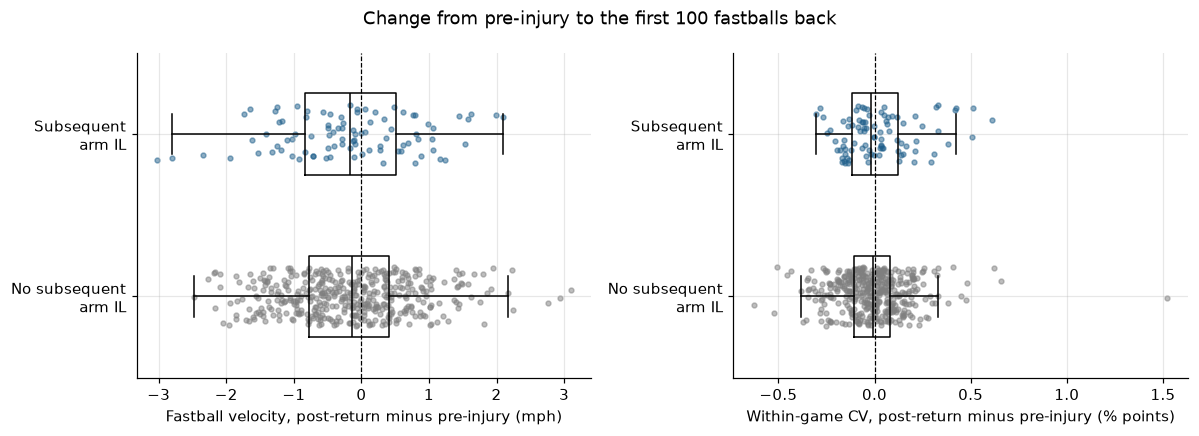

In [19]:
from math import erf, sqrt


def Phi(x):
    return 0.5 * (1 + erf(x / sqrt(2)))


def ranksum_test(x, y):
    """Two-sided Wilcoxon rank-sum (Mann-Whitney U) test, normal approximation with tie and continuity correction."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    x, y = x[~np.isnan(x)], y[~np.isnan(y)]
    n1, n2 = len(x), len(y)
    if n1 == 0 or n2 == 0:
        return np.nan, np.nan
    allv = np.r_[x, y]
    ranks = pd.Series(allv).rank().to_numpy()
    U = ranks[:n1].sum() - n1 * (n1 + 1) / 2
    n = n1 + n2
    _, t = np.unique(allv, return_counts=True)
    sigma = np.sqrt(n1 * n2 / 12 * ((n + 1) - (t ** 3 - t).sum() / (n * (n - 1))))
    z = (U - n1 * n2 / 2 - np.sign(U - n1 * n2 / 2) * 0.5) / sigma if sigma > 0 else 0.0
    return U, 2 * (1 - Phi(abs(z)))


# check against a hand-computed case: x = [1, 2], y = [3, 4] -> U = 0
assert ranksum_test([1, 2], [3, 4])[0] == 0


def table2(df):
    rows = []
    for var, label in [("d_velo", "Fastball velocity difference, mph"), ("mph_lost", "  mph lost"),
                       ("mph_gained", "  mph gained"), ("d_cv", "Within-game CV difference, % points")]:
        a, b = df.loc[df["case"] == 1, var], df.loc[df["case"] == 0, var]
        U, p = ranksum_test(a, b)
        rows.append({"Difference (post-return minus pre-injury)": label,
                     "Subsequent arm IL: mean (SD)": fmt_mean(a, 3), "median": f"{a.median():.3f}",
                     "No subsequent arm IL: mean (SD)": fmt_mean(b, 3), "median ": f"{b.median():.3f}",
                     "Wilcoxon rank-sum p": round(p, 4)})
    return pd.DataFrame(rows)


T2 = pd.concat([table2(D.loc[D["role"] == r]).assign(group=lab) for r, lab in
                [("starter", "Starters"), ("reliever", "Relievers")]] + [table2(D).assign(group="All")],
               ignore_index=True)
T2 = T2[["group"] + [c for c in T2.columns if c != "group"]]
T2.to_csv(OUT_DIR / "table2_differences.csv", index=False)
display(T2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rng_j = np.random.default_rng(SEED)
for ax, var, label in [(axes[0], "d_velo", "Fastball velocity, post-return minus pre-injury (mph)"),
                       (axes[1], "d_cv", "Within-game CV, post-return minus pre-injury (% points)")]:
    for k, (grp, color, name) in enumerate([(0, "#7f7f7f", "No subsequent arm IL"), (1, "#1f5f8b", "Subsequent arm IL")]):
        v = D.loc[D["case"] == grp, var].to_numpy()
        ax.scatter(v, k + rng_j.uniform(-0.18, 0.18, len(v)), s=10, alpha=0.5, color=color)
        try:
            ax.boxplot(v, positions=[k], orientation="horizontal", widths=0.5, showfliers=False,
                       medianprops={"color": "black"})
        except TypeError:                                   # matplotlib < 3.10
            ax.boxplot(v, positions=[k], vert=False, widths=0.5, showfliers=False, medianprops={"color": "black"})
    ax.axvline(0, color="black", lw=0.8, ls="--")
    ax.set_yticks([0, 1], ["No subsequent\narm IL", "Subsequent\narm IL"])
    ax.set_xlabel(label)
fig.suptitle(f"Change from pre-injury to the first {LANDMARK_FB} fastballs back")
fig.tight_layout()
save(fig, "V1_differences_by_outcome")

## 10. Logistic regression

Outcome: subsequent arm IL placement after the landmark (yes/no). Odds ratios with **pitcher-clustered
(robust) 95% CIs**, because some pitchers contribute more than one season.

| Model | Terms |
|---|---|
| **Primary (prespecified)** | mph lost, mph gained, CV difference (per `CV_SCALE` % points), age, role (starter: > 3.0 IP per appearance), IL era |
| **Role interaction (prespecified)** | primary + mph lost × starter + mph gained × starter; gives the odds ratios **within** starters and relievers and a joint 2-df Wald test of whether they differ |
| Unadjusted | mph lost, mph gained, CV difference |
| 2022-paper form | velocity difference (one linear term), CV difference |

IL era stays in the primary model because the seasons span two changes in the IL minimum (Section 12 shows
the model without it). Initial injury site and days on the IL are added in a sensitivity analysis.

The cell prints events per parameter; below about 10, read the intervals as rough.

In [20]:
def fit_logit(X, y, groups, ridge=1e-6, max_iter=200):
    """Logistic regression (Newton with step-halving) and pitcher-clustered sandwich covariance."""
    beta = np.zeros(X.shape[1])
    beta[0] = np.log(max(y.mean(), 1e-6) / max(1 - y.mean(), 1e-6))
    pen = ridge * np.eye(X.shape[1]); pen[0, 0] = 0
    nll = lambda b: np.sum(np.logaddexp(0, X @ b) - y * (X @ b)) + 0.5 * b @ pen @ b
    converged = False
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-(X @ beta)))
        H = X.T @ (X * (p * (1 - p))[:, None]) + pen
        step = np.linalg.lstsq(H, X.T @ (y - p) - pen @ beta, rcond=None)[0]
        t, f0 = 1.0, nll(beta)
        while nll(beta + t * step) > f0 + 1e-10 and t > 1e-8:
            t /= 2
        beta = beta + t * step
        if np.max(np.abs(t * step)) < 1e-9:
            converged = True
            break
    p = 1 / (1 + np.exp(-(X @ beta)))
    Hinv = np.linalg.pinv(X.T @ (X * (p * (1 - p))[:, None]) + pen)
    scores = pd.DataFrame(X * (y - p)[:, None]).groupby(groups).sum().to_numpy()
    G = scores.shape[0]
    V = Hinv @ (scores.T @ scores) @ Hinv * G / max(G - 1, 1)
    return beta, V, converged


def auc(score, y):
    pos, neg = score[y == 1], score[y == 0]
    if not len(pos) or not len(neg):
        return np.nan
    return ((pos[:, None] > neg[None, :]) + 0.5 * (pos[:, None] == neg[None, :])).mean()


TERM_LABEL = {"mph_lost": "Velocity lost, per mph", "mph_gained": "Velocity gained, per mph",
              "d_velo": "Velocity difference, per mph (post minus pre)",
              "d_cv_scaled": f"Within-game CV difference, per {CV_SCALE} % points",
              "starter": "Starter (> 3.0 IP per appearance, vs reliever)", "age": "Age at return, per year",
              "elbow_initial": "Initial injury elbow/forearm (vs shoulder / other arm)",
              "log_il_days": "log(days on IL)"}


def fit_model(df, terms, label):
    df = df.dropna(subset=terms)
    X = np.column_stack([np.ones(len(df))] + [df[t].to_numpy(float) for t in terms])
    y = df["case"].to_numpy(float)
    beta, V, ok = fit_logit(X, y, df["pkey"].to_numpy())
    se = np.sqrt(np.diag(V))
    tab = pd.DataFrame({"model": label, "term": ["(intercept)"] + [TERM_LABEL.get(t, t) for t in terms],
                        "beta": beta, "robust SE": se, "OR": np.exp(beta),
                        "OR lower95": np.exp(beta - 1.96 * se), "OR upper95": np.exp(beta + 1.96 * se),
                        "p": [2 * (1 - Phi(abs(b / s))) if s > 0 else np.nan for b, s in zip(beta, se)]})
    info = {"model": label, "pitcher-seasons": len(df), "events": int(y.sum()), "pitchers": df["pkey"].nunique(),
            "parameters": len(beta), "events per parameter": round(y.sum() / len(beta), 1),
            "in-sample AUC": auc(X @ beta, y), "converged": ok}
    if np.max(np.abs(beta[1:])) > 8 or info["in-sample AUC"] > 0.99:
        print(f"  Warning ({label}): near-complete separation (a coefficient > 8 in absolute value or AUC > 0.99); "
              "odds ratios and intervals are not interpretable.")
    return tab, info, beta, V, df


ERA_TERMS = [c for c in D.columns if c.startswith("era: ") and 0 < D[c].sum() < len(D)]
COVARIATES = (["age"] if USE_AGE else []) + ["starter"] + ERA_TERMS
EXTRA_COVARIATES = ["elbow_initial", "log_il_days"]          # added in the "fuller adjustment" sensitivity
PRIMARY_TERMS = ["mph_lost", "mph_gained", "d_cv_scaled"] + COVARIATES
models = [("Primary (adjusted)", PRIMARY_TERMS),
          ("Unadjusted", ["mph_lost", "mph_gained", "d_cv_scaled"]),
          ("2022-paper form", ["d_velo", "d_cv_scaled"])]
fits = {label: fit_model(D, terms, label) for label, terms in models}
model_tab = pd.concat([f[0] for f in fits.values()], ignore_index=True)
model_info = pd.DataFrame([f[1] for f in fits.values()])
model_tab.to_csv(OUT_DIR / "logistic_models.csv", index=False)
model_info.to_csv(OUT_DIR / "logistic_models_info.csv", index=False)
display(model_info)
show = model_tab.loc[model_tab["term"] != "(intercept)"].copy()
show["OR (95% CI)"] = [f"{o:.2f} ({l:.2f}–{u:.2f})" for o, l, u in zip(show["OR"], show["OR lower95"], show["OR upper95"])]
with pd.option_context("display.max_colwidth", 70):
    display(show[["model", "term", "OR (95% CI)", "p"]].round(4))
if not USE_AGE:
    print("Age was not available for enough units and is not in the adjusted model.")


def fit_role_interaction(df, terms, label):
    """terms + velocity x starter. Returns role-specific odds ratios, the joint Wald test, and the fit."""
    df = df.copy()
    df["mph_lost_x_starter"] = df["mph_lost"] * df["starter"]
    df["mph_gained_x_starter"] = df["mph_gained"] * df["starter"]
    t_all = terms + ["mph_lost_x_starter", "mph_gained_x_starter"]
    tab, info, beta, V, used = fit_model(df, t_all, label)
    rows = []
    for term in ["mph_lost", "mph_gained"]:
        i, j = 1 + t_all.index(term), 1 + t_all.index(f"{term}_x_starter")
        for role_name, c in [("relievers", np.eye(len(beta))[i]), ("starters", np.eye(len(beta))[i] + np.eye(len(beta))[j])]:
            b, se = c @ beta, np.sqrt(c @ V @ c)
            rows.append({"term": TERM_LABEL[term], "role": role_name, "OR": np.exp(b), "lower95": np.exp(b - 1.96 * se),
                         "upper95": np.exp(b + 1.96 * se), "p": 2 * (1 - Phi(abs(b / se))) if se > 0 else np.nan})
    idx = [1 + t_all.index("mph_lost_x_starter"), 1 + t_all.index("mph_gained_x_starter")]
    stat = float(beta[idx] @ np.linalg.pinv(V[np.ix_(idx, idx)]) @ beta[idx])
    wald = {"joint Wald chi2 (2 df)": stat, "p": float(np.exp(-stat / 2))}     # chi2(2) survival = exp(-x/2)
    return pd.DataFrame(rows), wald, (t_all, beta, V, used, info)


role_events = D.groupby("role")["case"].sum().reindex(["starter", "reliever"]).fillna(0).astype(int)
print("Events after the landmark by role:", role_events.to_dict())
role_fit = None
if role_events.min() < 5:
    print("Fewer than 5 events in a role: the role-interaction model is not fitted (Section 11 is skipped). "
          "Consider a smaller LANDMARK_FB (see the flow table in Section 7).")
else:
  role_or, role_wald, role_fit = fit_role_interaction(D, PRIMARY_TERMS, "Role interaction")
  role_or["OR (95% CI)"] = [f"{o:.2f} ({l:.2f}–{u:.2f})" for o, l, u in zip(role_or["OR"], role_or["lower95"], role_or["upper95"])]
  role_or.to_csv(OUT_DIR / "role_specific_odds_ratios.csv", index=False)
  display(pd.DataFrame([role_fit[4]]))
  print(f"Does the velocity association differ between starters and relievers? joint Wald chi2 (2 df) = "
        f"{role_wald['joint Wald chi2 (2 df)']:.2f}, p = {role_wald['p']:.4f}")
  display(role_or[["term", "role", "OR (95% CI)", "p"]].round(4))

,model,pitcher-seasons,events,pitchers,parameters,events per parameter,in-sample AUC,converged
0,Primary (adjusted),517,91,401,8,11.4,0.619022,True
1,Unadjusted,517,91,401,4,22.8,0.535650,True
2,2022-paper form,517,91,401,3,30.3,0.521153,True


,model,term,OR (95% CI),p
1,Primary (adjusted),"Velocity lost, per mph",1.21 (0.78–1.89),0.3879
2,Primary (adjusted),"Velocity gained, per mph",1.16 (0.70–1.93),0.5585
3,Primary (adjusted),"Within-game CV difference, per 0.1 % points",1.10 (0.98–1.23),0.1239
4,Primary (adjusted),"Age at return, per year",0.92 (0.84–1.00),0.0470
5,Primary (adjusted),"Starter (> 3.0 IP per appearance, vs reliever)",1.07 (0.67–1.71),0.7857
6,Primary (adjusted),era: 10-day DL/IL (2017-21),2.27 (0.71–7.23),0.1668
7,Primary (adjusted),"era: 15-day IL, pitchers (2022-)",2.46 (0.78–7.81),0.1254
9,Unadjusted,"Velocity lost, per mph",1.16 (0.75–1.81),0.4971
10,Unadjusted,"Velocity gained, per mph",1.19 (0.73–1.94),0.4731
11,Unadjusted,"Within-game CV difference, per 0.1 % points",1.09 (0.97–1.23),0.1422


Events after the landmark by role: {'starter': 51, 'reliever': 40}


,model,pitcher-seasons,events,pitchers,parameters,events per parameter,in-sample AUC,converged
0,Role interaction,517,91,401,10,9.1,0.664216,True


Does the velocity association differ between starters and relievers? joint Wald chi2 (2 df) = 11.99, p = 0.0025


,term,role,OR (95% CI),p
0,"Velocity lost, per mph",relievers,0.42 (0.19–0.94),0.0345
1,"Velocity lost, per mph",starters,2.24 (1.36–3.70),0.0016
2,"Velocity gained, per mph",relievers,0.44 (0.11–1.76),0.2489
3,"Velocity gained, per mph",starters,1.86 (1.05–3.27),0.0324


## 11. Predicted risk by velocity change, starters and relievers (role-interaction model)

Predicted probability of a subsequent arm IL after the landmark as the post-return velocity difference
varies, from the role-interaction model, with the other terms at the averages of that role's own
pitcher-seasons (95% CI by the delta method on the logit scale). The table gives the same at round values.

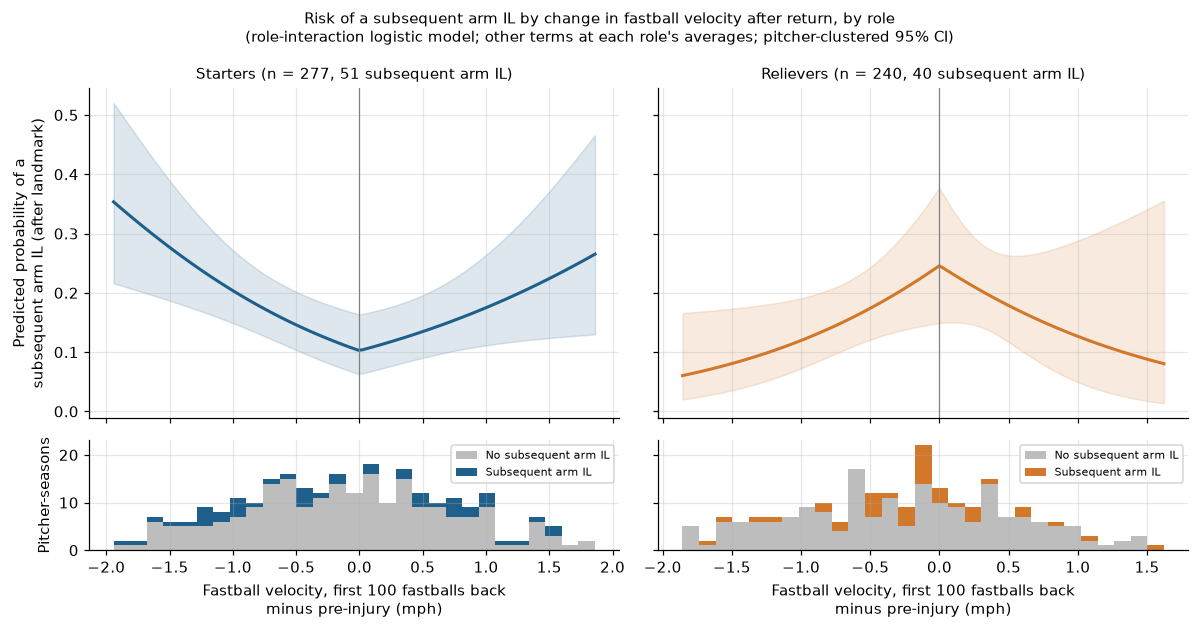

role,Relievers,Starters
velocity change (mph),,
-2.0,0.054,0.364
-1.5,0.081,0.277
-1.0,0.120,0.204
-0.5,0.174,0.146
0.0,0.246,0.103
0.5,0.179,0.135
1.0,0.127,0.175
1.5,0.088,0.224
2.0,0.061,0.282


Full table with 95% CIs: predicted_risk_by_role.csv


In [21]:
if role_fit is None:
    print("Role-interaction model not fitted (too few events in a role); see Section 10.")
else:
    expit = lambda z: 1 / (1 + np.exp(-z))
    terms_r, beta_r, V_r, D_r, _ = role_fit
    D_r = D_r.copy()
    ROLE_GROUPS = [(1.0, "Starters", "#1f5f8b"), (0.0, "Relievers", "#d1782a")]


    def design_role(dv, starter):
        x0 = D_r.loc[D_r["starter"] == starter, terms_r].mean()
        rows = []
        for v in np.atleast_1d(dv):
            x = x0.copy()
            x["starter"] = starter
            x["mph_lost"], x["mph_gained"] = max(-v, 0), max(v, 0)
            x["mph_lost_x_starter"], x["mph_gained_x_starter"] = x["mph_lost"] * starter, x["mph_gained"] * starter
            rows.append(np.r_[1.0, x[terms_r].to_numpy(float)])
        return np.array(rows)


    fig, axes = plt.subplots(2, 2, figsize=(11, 5.8), sharex="col", sharey="row", gridspec_kw={"height_ratios": [3, 1]})
    risk_rows = []
    pts = np.array([-2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2])
    for col, (st, name, color) in enumerate(ROLE_GROUPS):
        sub = D_r.loc[D_r["starter"] == st]
        grid = np.linspace(*np.nanpercentile(sub["d_velo"], [2.5, 97.5]), 121)
        Xg = design_role(grid, st)
        eta, se = Xg @ beta_r, np.sqrt(np.einsum("ij,jk,ik->i", Xg, V_r, Xg))
        ax = axes[0, col]
        ax.plot(grid, expit(eta), color=color, lw=2)
        ax.fill_between(grid, expit(eta - 1.96 * se), expit(eta + 1.96 * se), color=color, alpha=0.15)
        ax.axvline(0, color="grey", lw=0.8)
        ax.set_title(f"{name} (n = {len(sub)}, {int(sub['case'].sum())} subsequent arm IL)", fontsize=10)
        if col == 0:
            ax.set_ylabel("Predicted probability of a\nsubsequent arm IL (after landmark)")
        axh = axes[1, col]
        bins = np.linspace(grid.min(), grid.max(), 30)
        axh.hist([sub.loc[sub["case"] == 0, "d_velo"], sub.loc[sub["case"] == 1, "d_velo"]], bins=bins, stacked=True,
                 color=["#bdbdbd", color], label=["No subsequent arm IL", "Subsequent arm IL"])
        axh.set_xlabel(f"Fastball velocity, first {LANDMARK_FB} fastballs back\nminus pre-injury (mph)")
        axh.legend(fontsize=7)
        Xp = design_role(pts, st)
        ep, sp = Xp @ beta_r, np.sqrt(np.einsum("ij,jk,ik->i", Xp, V_r, Xp))
        risk_rows += [{"role": name, "velocity change (mph)": p, "predicted risk": r, "lower95": l, "upper95": u}
                      for p, r, l, u in zip(pts, expit(ep), expit(ep - 1.96 * sp), expit(ep + 1.96 * sp))]
    axes[1, 0].set_ylabel("Pitcher-seasons")
    fig.suptitle("Risk of a subsequent arm IL by change in fastball velocity after return, by role\n"
                 "(role-interaction logistic model; other terms at each role's averages; pitcher-clustered 95% CI)",
                 fontsize=10)
    fig.tight_layout()
    save(fig, "V2_predicted_risk_by_velocity_change_by_role")
    role_risk = pd.DataFrame(risk_rows)
    role_risk.to_csv(OUT_DIR / "predicted_risk_by_role.csv", index=False)
    display(role_risk.pivot(index="velocity change (mph)", columns="role", values="predicted risk").round(3))
    print("Full table with 95% CIs: predicted_risk_by_role.csv")

## 12. Sensitivity analyses (primary and role-interaction models refitted)

| Variant | Change |
|---|---|
| landmark 100 / 150 fastballs | exposure over the first 100 or 150 primary fastballs (`LANDMARK_FB_SENS`) |
| landmark 5 appearances | the v5 design (exposure over the first 5 appearances back) |
| role cut-off 2.5 / 4.0 IP | starter = more than 2.5 (or 4.0) innings per appearance |
| role from post-return outings | innings per appearance over the landmark appearances |
| fuller adjustment | primary + initial injury elbow/forearm + log(days on IL) |
| one season per pitcher | earliest analysed season per pitcher only |
| elbow → elbow | initial elbow/forearm injury; outcome = subsequent elbow/forearm IL |
| season-adjusted | primary model + season indicators |
| ≥ 5 pre-injury games | stricter baseline |
| no era adjustment | primary model without the IL-era terms |
| pre-injury window within one tracking system | pre-injury velocity and CV from games tracked by the monitored season's system |
| no pre-injury window across a tracking change | pitcher-seasons whose window crosses a change dropped |
| 2021–2026 only / 2016–2019 only | FanGraphs seasons / seasons rebuilt from MLB transactions |
| leave one season out | models refitted without each season in turn (stability) |

The first table and figure give the pooled odds ratios (primary model); the second give the **role-specific**
velocity odds ratios (role-interaction model) for each variant.

,,term,"Velocity lost, per mph","Velocity gained, per mph","Within-game CV difference, per 0.1 % points"
variant,pitcher-seasons,events,,,
main,517,91,1.21 (0.78–1.89),1.16 (0.70–1.93),1.10 (0.98–1.23)
landmark 100 fastballs,517,91,1.21 (0.78–1.89),1.16 (0.70–1.93),1.10 (0.98–1.23)
landmark 150 fastballs,430,67,1.71 (1.05–2.78),1.26 (0.66–2.40),1.16 (1.02–1.32)
landmark 5 appearances,536,102,1.44 (0.97–2.15),1.46 (0.89–2.40),1.10 (0.99–1.22)
role cut-off 2.5 IP,517,91,1.21 (0.78–1.88),1.16 (0.70–1.92),1.09 (0.98–1.23)
role cut-off 4.0 IP,517,91,1.22 (0.78–1.89),1.17 (0.71–1.95),1.10 (0.98–1.23)
role from post-return outings,517,91,1.20 (0.78–1.86),1.19 (0.70–2.03),1.09 (0.97–1.22)
fuller adjustment,517,91,1.27 (0.82–1.97),1.20 (0.73–1.99),1.09 (0.96–1.22)
no era adjustment,517,91,1.18 (0.76–1.83),1.14 (0.69–1.87),1.08 (0.96–1.21)


,,,term,"Velocity lost, per mph: relievers","Velocity lost, per mph: starters","Velocity gained, per mph: relievers","Velocity gained, per mph: starters"
variant,starters (events),relievers (events),interaction p,,,,
main,277 (51),240 (40),0.002493,0.42 (0.19–0.94),2.24 (1.36–3.70),0.44 (0.11–1.76),1.86 (1.05–3.27)
landmark 100 fastballs,277 (51),240 (40),0.002493,0.42 (0.19–0.94),2.24 (1.36–3.70),0.44 (0.11–1.76),1.86 (1.05–3.27)
landmark 150 fastballs,255 (44),175 (23),0.238683,0.87 (0.34–2.25),2.25 (1.28–3.97),0.50 (0.06–4.51),1.68 (0.85–3.34)
landmark 5 appearances,283 (54),253 (48),0.016976,0.72 (0.37–1.40),2.41 (1.44–4.05),0.64 (0.22–1.86),2.17 (1.23–3.84)
role cut-off 2.5 IP,291 (54),226 (37),0.002780,0.38 (0.16–0.91),2.15 (1.32–3.49),0.51 (0.13–2.00),1.68 (0.98–2.88)
role cut-off 4.0 IP,249 (44),268 (47),0.031253,0.61 (0.29–1.29),2.08 (1.23–3.49),0.82 (0.35–1.96),1.57 (0.85–2.90)
role from post-return outings,263 (53),254 (38),0.002962,0.42 (0.19–0.96),2.19 (1.31–3.66),0.56 (0.21–1.47),2.48 (1.10–5.59)
fuller adjustment,277 (51),240 (40),0.003648,0.45 (0.20–1.01),2.29 (1.37–3.81),0.46 (0.12–1.79),1.93 (1.08–3.47)
no era adjustment,277 (51),240 (40),0.002392,0.41 (0.18–0.92),2.20 (1.33–3.62),0.46 (0.12–1.80),1.75 (1.02–3.03)


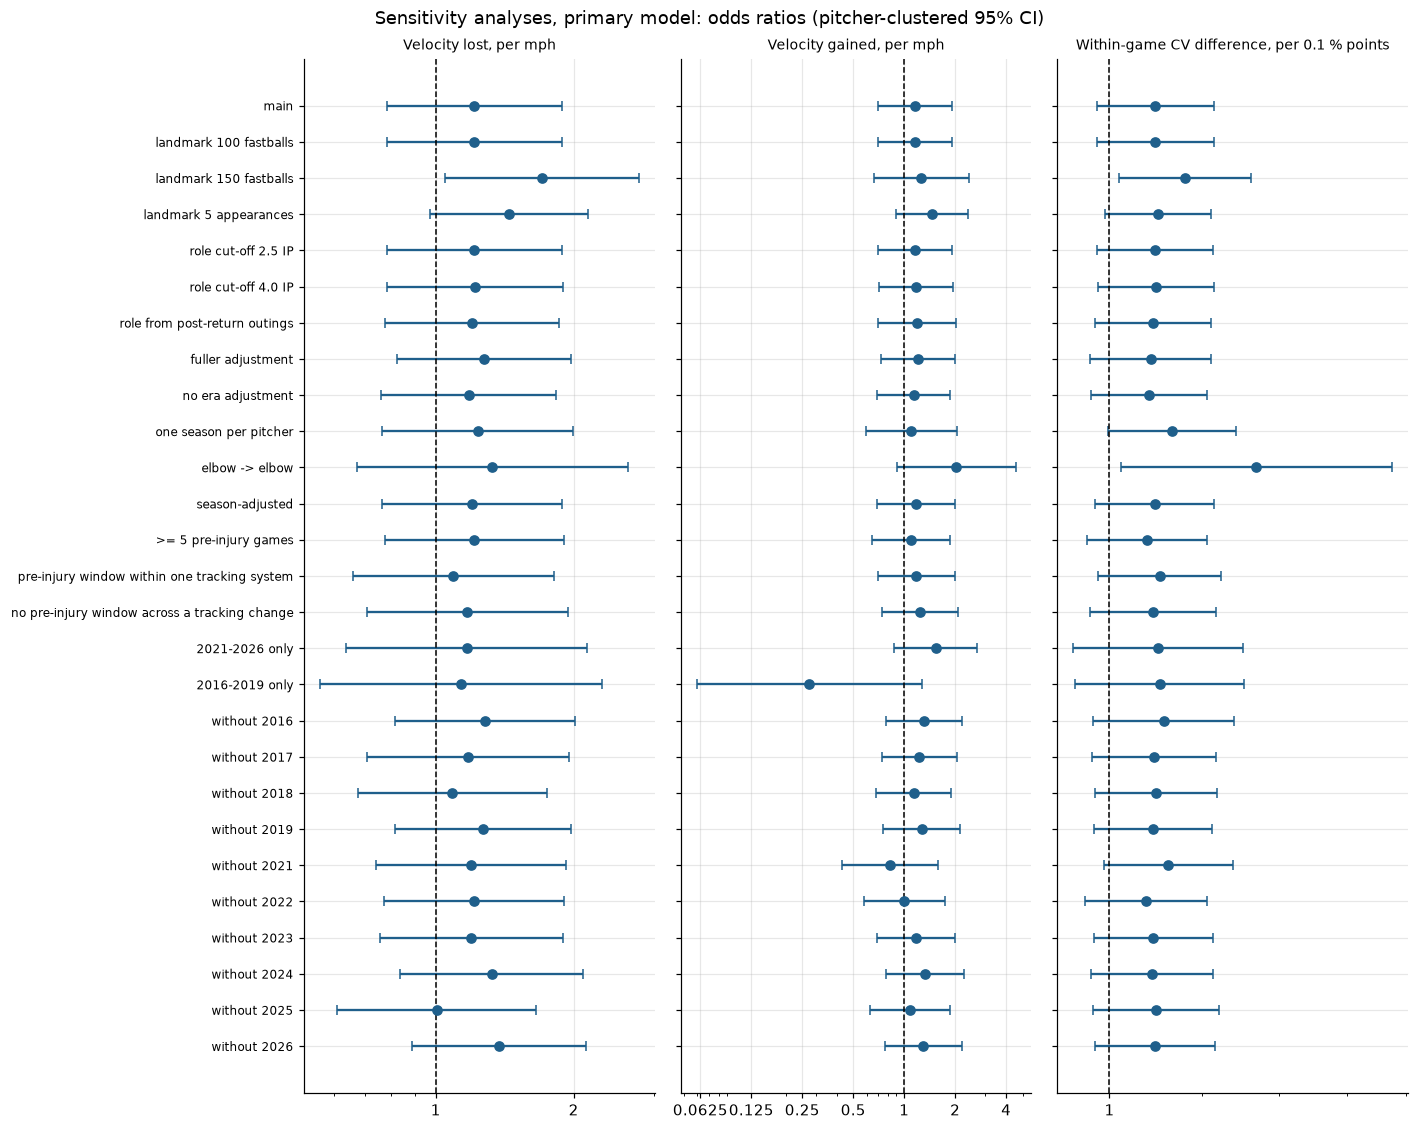

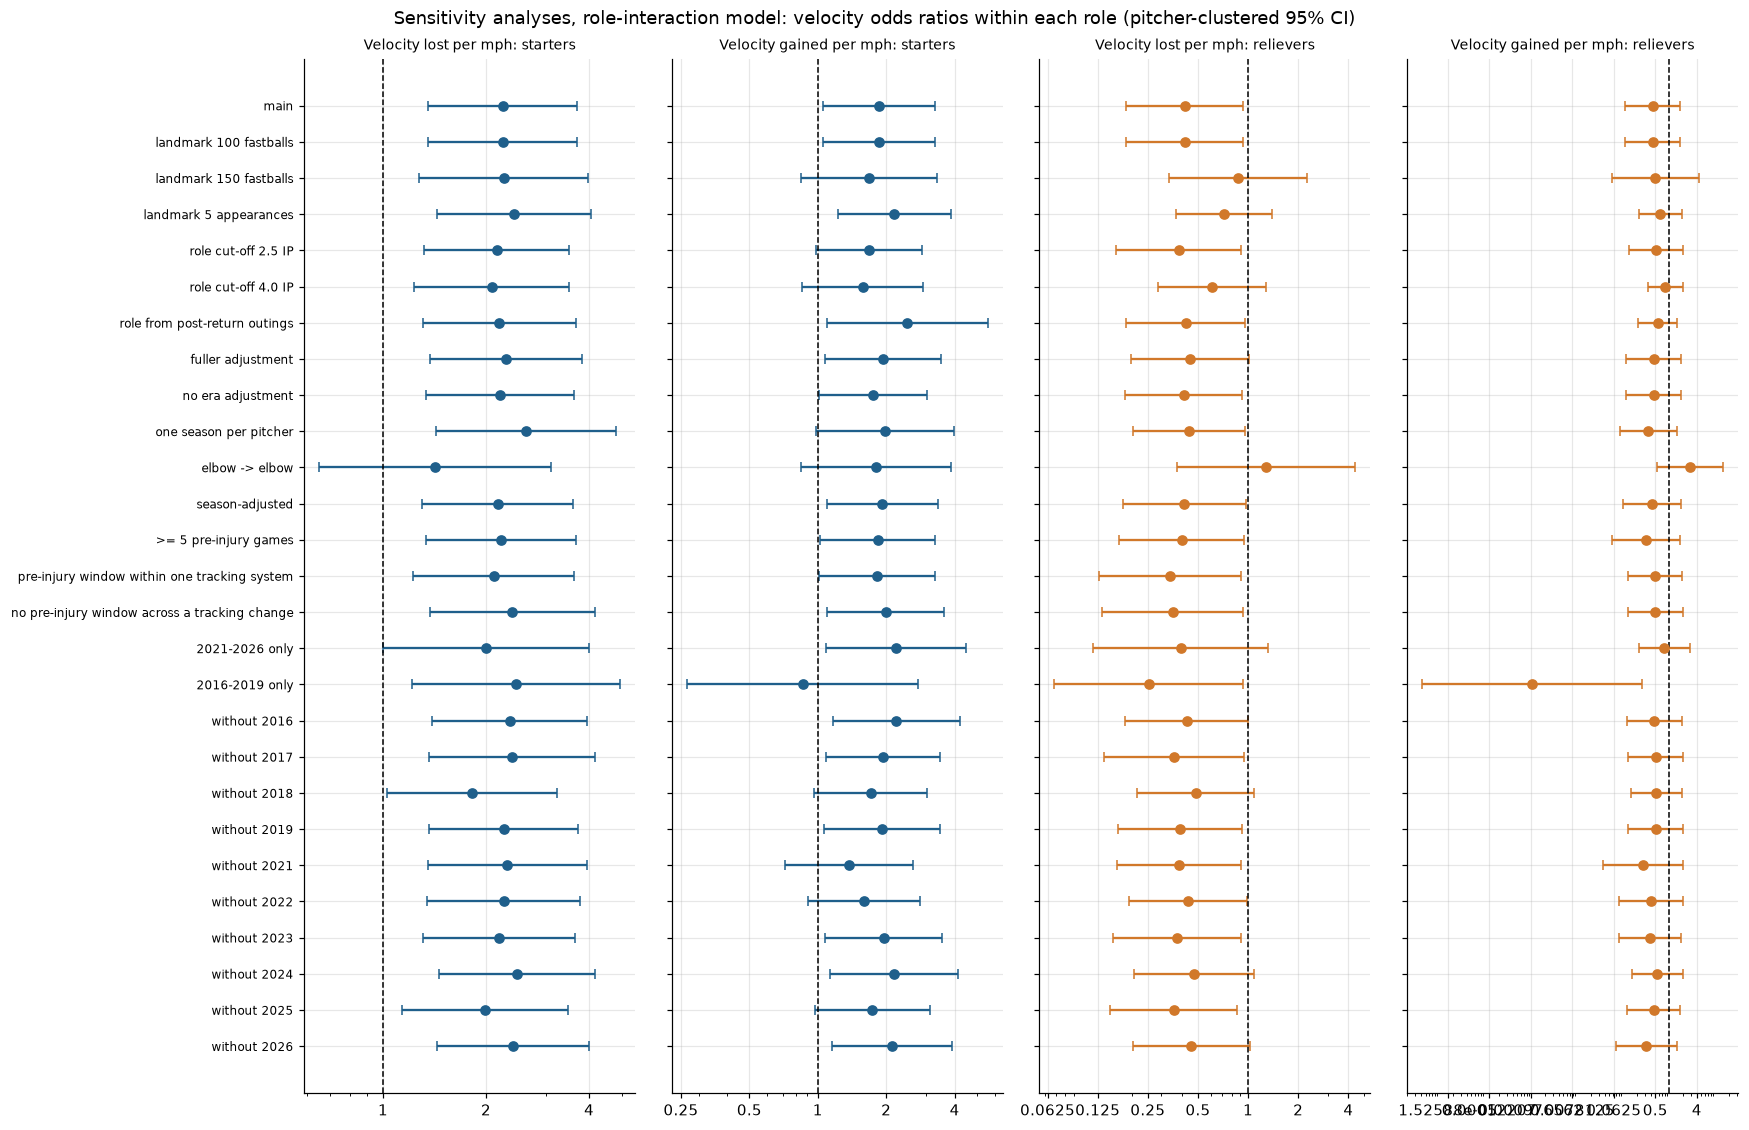

In [22]:
NO_ERA = [t for t in PRIMARY_TERMS if t not in ERA_TERMS]
import matplotlib.ticker
key_terms = ["Velocity lost, per mph", "Velocity gained, per mph", f"Within-game CV difference, per {CV_SCALE} % points"]
sens, sens_role = [], []


def era_terms_for(df, base=None):
    base = NO_ERA if base is None else base
    return base + [t for t in ERA_TERMS if 0 < df[t].sum() < len(df)]


def add(label, df, terms=None):
    df = df.dropna(subset=["d_velo", "d_cv"])
    terms = era_terms_for(df) if terms is None else terms
    if df["case"].sum() < 5:
        print(f"{label}: fewer than 5 events, skipped")
        return
    tab, info, *_ = fit_model(df, terms, label)
    for _, r in tab.loc[tab["term"].isin(key_terms)].iterrows():
        sens.append({"variant": label, "pitcher-seasons": info["pitcher-seasons"], "events": info["events"],
                     "term": r["term"], "OR": r["OR"], "lower95": r["OR lower95"], "upper95": r["OR upper95"], "p": r["p"]})
    if "starter" in terms and df["starter"].nunique() == 2 and min(df.groupby("starter")["case"].sum()) >= 5:
        ror, wald, fit = fit_role_interaction(df, terms, label)
        for _, r in ror.iterrows():
            sens_role.append({"variant": label, "starters (events)": f"{int((df['starter'] == 1).sum())} ({int(df.loc[df['starter'] == 1, 'case'].sum())})",
                              "relievers (events)": f"{int((df['starter'] == 0).sum())} ({int(df.loc[df['starter'] == 0, 'case'].sum())})",
                              "term": f"{r['term']}: {r['role']}", "OR": r["OR"], "lower95": r["lower95"],
                              "upper95": r["upper95"], "p": r["p"], "interaction p": wald["p"]})


def included(f):
    return f.loc[f["status"] == "included"]


add("main", D, PRIMARY_TERMS)
for lfb in LANDMARK_FB_SENS:
    add(f"landmark {lfb} fastballs", included(landmark_frame(L_FB=lfb)))
add("landmark 5 appearances", included(landmark_frame(L_APPS=5)))
for cutoff in ROLE_CUTOFF_SENS:
    add(f"role cut-off {cutoff} IP", included(landmark_frame(role_cut=cutoff)))
add("role from post-return outings", included(landmark_frame(role_from="post")))
add("fuller adjustment", D, PRIMARY_TERMS + EXTRA_COVARIATES)
add("no era adjustment", D, NO_ERA)
first_season = D.sort_values("Season").groupby("pkey").head(1)
add("one season per pitcher", first_season)
LME = landmark_frame(outcome_group="elbow")
add("elbow -> elbow", LME.loc[(LME["status"] == "included") & (LME["elbow_initial"] == 1)])
seasons_present = sorted(D["Season"].unique())
for s_ in seasons_present[1:]:
    D[f"season_{s_}"] = (D["Season"] == s_).astype(float)
add("season-adjusted", D, NO_ERA + [f"season_{s_}" for s_ in seasons_present[1:]])   # seasons nest eras
add(">= 5 pre-injury games", D.loc[D["n_pre_games"] >= 5])
add("pre-injury window within one tracking system", included(landmark_frame(same_system=True)))
add("no pre-injury window across a tracking change", D.loc[~D["baseline_crosses_system"].astype(bool)])
add("2021-2026 only", D.loc[D["Season"] >= 2021])
add("2016-2019 only", D.loc[D["Season"] <= 2019])
for s_ in seasons_present:
    add(f"without {s_}", D.loc[D["Season"] != s_])
sensitivity = pd.DataFrame(sens)
sensitivity.to_csv(OUT_DIR / "sensitivity_models.csv", index=False)
sensitivity["OR (95% CI)"] = [f"{o:.2f} ({l:.2f}–{u:.2f})" for o, l, u in
                              zip(sensitivity["OR"], sensitivity["lower95"], sensitivity["upper95"])]
display(sensitivity.pivot_table(index=["variant", "pitcher-seasons", "events"], columns="term",
                                values="OR (95% CI)", aggfunc="first", sort=False))
sensitivity_role = pd.DataFrame(sens_role)
sensitivity_role.to_csv(OUT_DIR / "sensitivity_role_specific.csv", index=False)
sensitivity_role["OR (95% CI)"] = [f"{o:.2f} ({l:.2f}–{u:.2f})" for o, l, u in
                                   zip(sensitivity_role["OR"], sensitivity_role["lower95"], sensitivity_role["upper95"])]
display(sensitivity_role.pivot_table(index=["variant", "starters (events)", "relievers (events)", "interaction p"],
                                     columns="term", values="OR (95% CI)", aggfunc="first", sort=False).round(4))

fig, axes = plt.subplots(1, 3, figsize=(13, 0.32 * sensitivity["variant"].nunique() + 1.8), sharey=True)
variants_order = list(dict.fromkeys(sensitivity["variant"]))
for ax, term in zip(axes, key_terms):
    s = sensitivity.loc[sensitivity["term"] == term].set_index("variant").reindex(variants_order)
    y = np.arange(len(s))[::-1]
    ax.errorbar(s["OR"], y, xerr=[s["OR"] - s["lower95"], s["upper95"] - s["OR"]], fmt="o", capsize=3, color="#1f5f8b")
    ax.axvline(1, color="black", ls="--", lw=1)
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(matplotlib.ticker.LogLocator(base=2, subs=(1.0,)))
    ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%g"))
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.set_title(term, fontsize=9)
    ax.set_yticks(y, variants_order, fontsize=8)
fig.suptitle("Sensitivity analyses, primary model: odds ratios (pitcher-clustered 95% CI)")
fig.tight_layout()
save(fig, "V3_sensitivity")

role_terms = [f"{TERM_LABEL[t]}: {r}" for r in ["starters", "relievers"] for t in ["mph_lost", "mph_gained"]]
fig, axes = plt.subplots(1, 4, figsize=(16, 0.32 * sensitivity_role["variant"].nunique() + 1.8), sharey=True)
order_r = list(dict.fromkeys(sensitivity_role["variant"]))
for ax, term in zip(axes, role_terms):
    s_ = sensitivity_role.loc[sensitivity_role["term"] == term].set_index("variant").reindex(order_r)
    y = np.arange(len(s_))[::-1]
    color = "#1f5f8b" if "starters" in term else "#d1782a"
    ax.errorbar(s_["OR"], y, xerr=[s_["OR"] - s_["lower95"], s_["upper95"] - s_["OR"]], fmt="o", capsize=3, color=color)
    ax.axvline(1, color="black", ls="--", lw=1)
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(matplotlib.ticker.LogLocator(base=2, subs=(1.0,)))
    ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%g"))
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.set_title(term.replace(", per mph", " per mph"), fontsize=9)
    ax.set_yticks(y, order_r, fontsize=8)
fig.suptitle("Sensitivity analyses, role-interaction model: velocity odds ratios within each role (pitcher-clustered 95% CI)")
fig.tight_layout()
save(fig, "V4_sensitivity_role_specific")

## 13. Notes for interpretation

* **Association, not prediction or cause.** A drop in velocity may be an early sign of an injury already
  developing; the landmark design ensures only that it is measured before the IL placement.
* **Reinjuries before the 300th fastball back** are outside the model by design (Section 7 counts them, by
  role). Relievers need many more appearances to get there, so more of their early reinjuries are excluded;
  the 100- and 150-fastball landmarks check how much this matters.
* **Role** is defined from innings per appearance before the injury (> 3.0 = starter), so it is fixed before
  the exposure; the cut-off and post-return-role rows of Section 12 check the definition. The difference
  between starters and relievers is the prespecified role interaction (Section 10).
* **Injury data** come from two sources, row-bound: rebuilt from MLB transactions for 2016–2019 and FanGraphs
  for 2021–2026. Publicly reported IL data from any source are subject to team reporting practices
  ("gamesmanship"), so injury dates and descriptions are approximate; the transactions rebuild reproduced 94%
  of FanGraphs' 2021–2023 pitcher stints.
* **Two directions.** "Velocity gained" tests the load hypothesis; read its odds ratio next to "velocity lost".
* **Multiple seasons per pitcher.** Intervals are pitcher-clustered; the one-season-per-pitcher row checks it.
* **Events per parameter.** With about 10 or fewer, intervals are approximate; the unadjusted model is the check.
* **2016–2019 rows** come from MLB transactions: IL dates can differ by a few days from FanGraphs, and
  rows with no injury text count as non-arm (Section 2 counts them).
* **Eras and tracking systems.** Read the primary result next to the "no era adjustment", "within one
  tracking system" and 2016–2019 vs 2021–2026 rows of Section 12.
* **Not adjusted for** ballpark or temperature (needs `home_team` from Statcast).